<a href="https://colab.research.google.com/github/Pradeepkalai/X-ray-Anomoly-Dectection/blob/main/XRay_Abnormality_Detection_Preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!nvidia-smi


/bin/bash: line 1: nvidia-smi: command not found


In [ ]:
!pip install -q kaggle


In [ ]:

from getpass import getpass
import os

os.environ["KAGGLE_API_TOKEN"] = getpass("KGAT_0ebcf6967144d3bc8bc7dae68900865e")

KGAT_0ebcf6967144d3bc8bc7dae68900865e··········


In [ ]:
!kaggle competitions list

You must authenticate before you can call the Kaggle API.
Follow the instructions to authenticate at: https://github.com/Kaggle/kaggle-cli/blob/main/docs/README.md#authentication


In [ ]:
!mkdir -p /content/nih_sample

!kaggle datasets download -d nih-chest-xrays/sample \
    -p /content/nih_sample \
    --unzip

Dataset URL: https://www.kaggle.com/datasets/nih-chest-xrays/sample
License(s): CC0-1.0
100% 4.20G/4.20G [00:44<00:00, 100MB/s] 



In [ ]:
import os

base_path = "/content/nih_sample"

print("Files/Folders:")
for item in os.listdir(base_path):
    print(item)

Files/Folders:
sample
sample_labels.csv


In [ ]:
import os

base_path = "/content/nih_sample"

print("Dataset contents:\n")

for item in os.listdir(base_path):
    print(item)

Dataset contents:

sample
sample_labels.csv


In [ ]:
import pandas as pd

labels_path = "/content/nih_sample/sample_labels.csv"

df = pd.read_csv(labels_path)

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Shape: (5606, 11)

Columns:
['Image Index', 'Finding Labels', 'Follow-up #', 'Patient ID', 'Patient Age', 'Patient Gender', 'View Position', 'OriginalImageWidth', 'OriginalImageHeight', 'OriginalImagePixelSpacing_x', 'OriginalImagePixelSpacing_y']

First 5 rows:


,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Gender,View Position,OriginalImageWidth,OriginalImageHeight,OriginalImagePixelSpacing_x,OriginalImagePixelSpacing_y
0,00000013_005.png,Emphysema|Infiltration|Pleural_Thickening|Pneu...,5,13,060Y,M,AP,3056,2544,0.139,0.139
1,00000013_026.png,Cardiomegaly|Emphysema,26,13,057Y,M,AP,2500,2048,0.168,0.168
2,00000017_001.png,No Finding,1,17,077Y,M,AP,2500,2048,0.168,0.168
3,00000030_001.png,Atelectasis,1,30,079Y,M,PA,2992,2991,0.143,0.143
4,00000032_001.png,Cardiomegaly|Edema|Effusion,1,32,055Y,F,AP,2500,2048,0.168,0.168


In [ ]:
import os

image_root = "/content/nih_sample/sample"

print("Number of files:", len(os.listdir(image_root)))

print("\nFirst 10 files:")
for file in os.listdir(image_root)[:10]:
    print(file)

Number of files: 3

First 10 files:
sample
images
sample_labels.csv


In [ ]:
import os

image_root = "/content/nih_sample/sample/images"

print("Number of images:", len(os.listdir(image_root)))

print("\nFirst 10 images:")
for file in os.listdir(image_root)[:10]:
    print(file)

Number of images: 5606

First 10 images:
00025448_001.png
00012628_060.png
00029755_003.png
00011678_000.png
00007126_000.png
00010531_010.png
00010718_002.png
00008168_009.png
00027427_011.png
00016368_000.png


Image shape: (1024, 1024, 3)


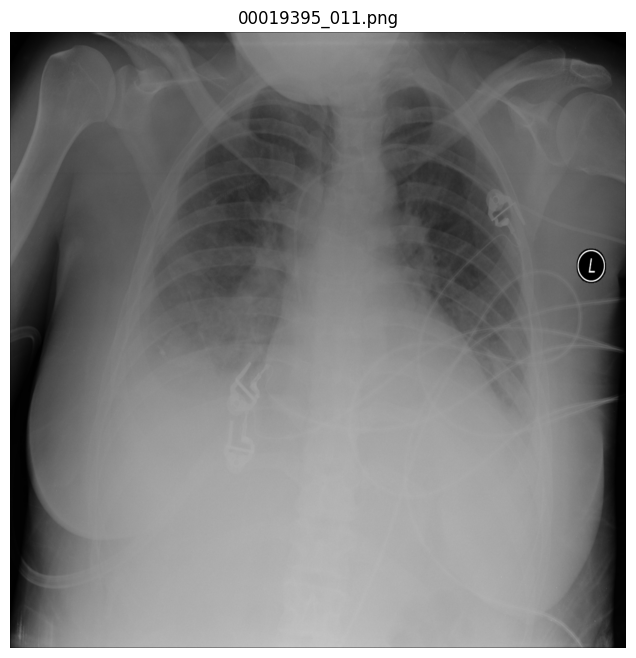

In [ ]:
import cv2
import matplotlib.pyplot as plt
import os

image_root = "/content/nih_sample/sample/images"

image_name = "00019395_011.png"
image_path = os.path.join(image_root, image_name)

img = cv2.imread(image_path)

# OpenCV BGR → RGB
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

print("Image shape:", img_rgb.shape)

plt.figure(figsize=(8, 8))
plt.imshow(img_rgb, cmap="gray")
plt.axis("off")
plt.title(image_name)
plt.show()

In [ ]:
!pip install -q albumentations

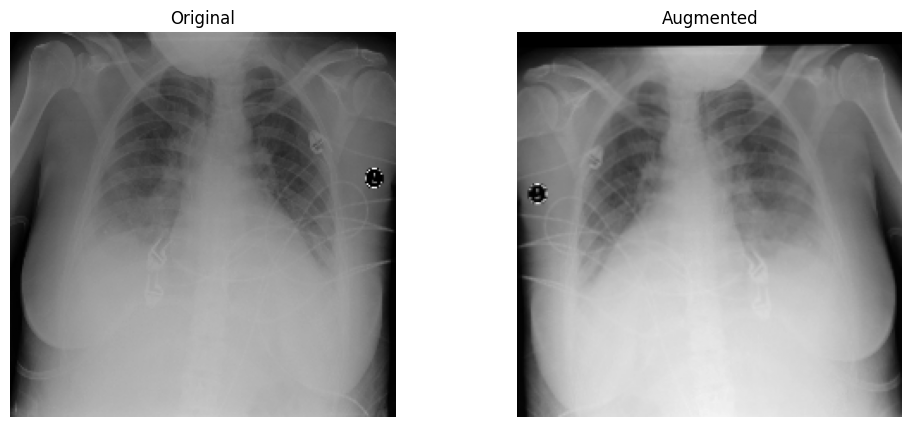

In [ ]:
import cv2
import matplotlib.pyplot as plt
import albumentations as A

# Image path
image_path = "/content/nih_sample/sample/images/00019395_011.png"

# 1. Load image
img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

# 2. Resize
img_resized = cv2.resize(img, (224, 224))

# 3. Augmentation
transform = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.RandomBrightnessContrast(
        brightness_limit=0.15,
        contrast_limit=0.15,
        p=0.5
    ),
    A.Affine(
        scale=(0.95, 1.05),
        translate_percent=(-0.05, 0.05),
        rotate=(-5, 5),
        p=0.5
    )
])

# 4. Apply augmentation
augmented = transform(image=img_resized)["image"]

# 5. Show original and augmented
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_resized, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(augmented, cmap="gray")
plt.title("Augmented")
plt.axis("off")

plt.show()

In [ ]:
import pandas as pd

labels_path = "/content/nih_sample/sample/sample_labels.csv"

df = pd.read_csv(labels_path)

# Get all individual labels
all_labels = set()

for labels in df["Finding Labels"]:
    for label in labels.split("|"):
        all_labels.add(label)

all_labels = sorted(all_labels)

print("Number of classes:", len(all_labels))
print("\nClasses:")
for i, label in enumerate(all_labels):
    print(i, "→", label)

Number of classes: 15

Classes:
0 → Atelectasis
1 → Cardiomegaly
2 → Consolidation
3 → Edema
4 → Effusion
5 → Emphysema
6 → Fibrosis
7 → Hernia
8 → Infiltration
9 → Mass
10 → No Finding
11 → Nodule
12 → Pleural_Thickening
13 → Pneumonia
14 → Pneumothorax


In [ ]:
import pandas as pd

# Exclude "No Finding" from disease classes
disease_classes = [
    label for label in all_labels
    if label != "No Finding"
]

# Multi-label encoding
for disease in disease_classes:
    df[disease] = df["Finding Labels"].apply(
        lambda x: int(disease in x.split("|"))
    )

print("Total Images:", len(df))
print("Number of Disease Classes:", len(disease_classes))

print("\nEncoded Labels:")
display(
    df[["Image Index", "Finding Labels"] + disease_classes].head()
)

print("\nDisease Distribution:")
print(df[disease_classes].sum().sort_values(ascending=False))

Total Images: 5606
Number of Disease Classes: 14

Encoded Labels:


,Image Index,Finding Labels,Atelectasis,Cardiomegaly,Consolidation,Edema,Effusion,Emphysema,Fibrosis,Hernia,Infiltration,Mass,Nodule,Pleural_Thickening,Pneumonia,Pneumothorax
0,00000013_005.png,Emphysema|Infiltration|Pleural_Thickening|Pneu...,0,0,0,0,0,1,0,0,1,0,0,1,0,1
1,00000013_026.png,Cardiomegaly|Emphysema,0,1,0,0,0,1,0,0,0,0,0,0,0,0
2,00000017_001.png,No Finding,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,00000030_001.png,Atelectasis,1,0,0,0,0,0,0,0,0,0,0,0,0,0
4,00000032_001.png,Cardiomegaly|Edema|Effusion,0,1,0,1,1,0,0,0,0,0,0,0,0,0



Disease Distribution:
Infiltration          967
Effusion              644
Atelectasis           508
Nodule                313
Mass                  284
Pneumothorax          271
Consolidation         226
Pleural_Thickening    176
Cardiomegaly          141
Emphysema             127
Edema                 118
Fibrosis               84
Pneumonia              62
Hernia                 13
dtype: int64


In [ ]:
from sklearn.model_selection import GroupShuffleSplit

# First: 80% train, 20% temporary
gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, temp_idx = next(
    gss.split(
        df,
        groups=df["Patient ID"]
    )
)

train_df = df.iloc[train_idx].reset_index(drop=True)
temp_df = df.iloc[temp_idx].reset_index(drop=True)

# Second: split remaining 20% into 10% validation + 10% test
gss2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_idx, test_idx = next(
    gss2.split(
        temp_df,
        groups=temp_df["Patient ID"]
    )
)

val_df = temp_df.iloc[val_idx].reset_index(drop=True)
test_df = temp_df.iloc[test_idx].reset_index(drop=True)

print("Train images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))

print("\nUnique patients:")
print("Train:", train_df["Patient ID"].nunique())
print("Validation:", val_df["Patient ID"].nunique())
print("Test:", test_df["Patient ID"].nunique())

Train images: 4462
Validation images: 566
Test images: 578

Unique patients:
Train: 3384
Validation: 423
Test: 423


In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import os
import numpy as np
import albumentations as A
from albumentations.pytorch import ToTensorV2

# Paths
image_root = "/content/nih_sample/sample/images"

# Training augmentation
train_transform = A.Compose([
    A.Resize(224, 224),
    A.HorizontalFlip(p=0.5),
    A.RandomBrightnessContrast(
        brightness_limit=0.15,
        contrast_limit=0.15,
        p=0.5
    ),
    A.Affine(
        scale=(0.95, 1.05),
        translate_percent=(-0.05, 0.05),
        rotate=(-5, 5),
        p=0.5
    ),
    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    ),
    ToTensorV2()
])

# Validation/Test: no augmentation
val_transform = A.Compose([
    A.Resize(224, 224),
    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    ),
    ToTensorV2()
])


class ChestXrayDataset(Dataset):

    def __init__(self, dataframe, image_dir, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image_path = os.path.join(
            self.image_dir,
            row["Image Index"]
        )

        # Read grayscale X-ray
        image = np.array(
            Image.open(image_path).convert("L")
        )

        # Convert grayscale → 3 channels
        image = np.stack(
            [image, image, image],
            axis=-1
        )

        # Apply transformation
        if self.transform:
            image = self.transform(image=image)["image"]

        # Multi-label target
        labels = row[disease_classes].values.astype(np.float32)
        labels = torch.tensor(labels)

        return image, labels


# Create datasets
train_dataset = ChestXrayDataset(
    train_df,
    image_root,
    train_transform
)

val_dataset = ChestXrayDataset(
    val_df,
    image_root,
    val_transform
)

test_dataset = ChestXrayDataset(
    test_df,
    image_root,
    val_transform
)


# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 140
Validation batches: 18
Test batches: 19


In [ ]:
import torch
import torch.nn as nn
from torchvision import models

# Use GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

# Load pretrained DenseNet121
model = models.densenet121(
    weights=models.DenseNet121_Weights.DEFAULT
)

# Number of output classes
num_classes = len(disease_classes)

# Replace original ImageNet classifier
model.classifier = nn.Linear(
    model.classifier.in_features,
    num_classes
)

# Move model to GPU
model = model.to(device)

print("Number of output classes:", num_classes)
print("Model: DenseNet121")

Using device: cpu
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 68.3MB/s]


Number of output classes: 14
Model: DenseNet121


In [ ]:
import torch
import torch.nn as nn

# --------------------------------
# Calculate class weights
# --------------------------------

positive_counts = train_df[disease_classes].sum()
negative_counts = len(train_df) - positive_counts

pos_weight = negative_counts / (positive_counts + 1e-6)

pos_weight = torch.tensor(
    pos_weight.values,
    dtype=torch.float32
).to(device)

# --------------------------------
# Loss function
# --------------------------------

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight
)

# --------------------------------
# Optimizer
# --------------------------------

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

print("Loss function: BCEWithLogitsLoss")
print("Optimizer: AdamW")
print("Learning rate: 0.0001")
print("Number of classes:", len(disease_classes))

Loss function: BCEWithLogitsLoss
Optimizer: AdamW
Learning rate: 0.0001
Number of classes: 14


In [ ]:
from tqdm.auto import tqdm
import torch

num_epochs = 5

for epoch in range(num_epochs):

    # -------------------------
    # TRAINING
    # -------------------------
    model.train()

    train_loss = 0.0

    progress_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{num_epochs} - Training"
    )

    for images, labels in progress_bar:

        images = images.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update model
        optimizer.step()

        train_loss += loss.item()

        progress_bar.set_postfix(
            loss=loss.item()
        )

    train_loss /= len(train_loader)

    # -------------------------
    # VALIDATION
    # -------------------------
    model.eval()

    val_loss = 0.0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            val_loss += loss.item()

    val_loss /= len(val_loader)

    print(
        f"\nEpoch {epoch+1}/{num_epochs} "
        f"| Train Loss: {train_loss:.4f} "
        f"| Val Loss: {val_loss:.4f}"
    )

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch 1/5 - Training:   0%|          | 0/140 [00:00<?, ?it/s]


Epoch 1/5 | Train Loss: 1.2530 | Val Loss: 1.1715


Epoch 2/5 - Training:   0%|          | 0/140 [00:00<?, ?it/s]

In [ ]:
import torch
import numpy as np
from sklearn.metrics import (
    roc_auc_score,
    f1_score,
    precision_score,
    recall_score
)

model.eval()

all_labels = []
all_probs = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        # Convert logits → probability
        probs = torch.sigmoid(outputs)

        all_labels.append(labels.numpy())
        all_probs.append(probs.cpu().numpy())

# Combine all batches
y_true = np.vstack(all_labels)
y_prob = np.vstack(all_probs)

# Convert probability to 0/1 prediction
y_pred = (y_prob >= 0.5).astype(int)

# Metrics
precision = precision_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

# AUROC
try:
    auroc = roc_auc_score(
        y_true,
        y_prob,
        average="macro"
    )
except ValueError:
    auroc = None

print("===== TEST RESULTS =====")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")

if auroc is not None:
    print(f"AUROC     : {auroc:.4f}")

In [ ]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_true,
        y_pred,
        target_names=disease_classes,
        zero_division=0
    )
)

In [ ]:
from sklearn.metrics import classification_report

report = classification_report(
    y_true,
    y_pred,
    target_names=disease_classes,
    zero_division=0
)

print(report)

In [ ]:
from sklearn.metrics import f1_score
import numpy as np
import torch

# --------------------------------
# Get validation predictions
# --------------------------------

model.eval()

val_true = []
val_prob = []

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)

        outputs = model(images)
        probs = torch.sigmoid(outputs)

        val_true.append(labels.numpy())
        val_prob.append(probs.cpu().numpy())

val_true = np.vstack(val_true)
val_prob = np.vstack(val_prob)

# --------------------------------
# Find best threshold
# --------------------------------

thresholds = np.arange(0.10, 0.91, 0.05)

best_threshold = 0.5
best_f1 = 0

for threshold in thresholds:

    val_pred = (val_prob >= threshold).astype(int)

    score = f1_score(
        val_true,
        val_pred,
        average="macro",
        zero_division=0
    )

    if score > best_f1:
        best_f1 = score
        best_threshold = threshold

print("Best threshold:", best_threshold)
print("Best Validation Macro F1:", round(best_f1, 4))

In [ ]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Use the best threshold found from validation set
tuned_y_pred = (y_prob >= best_threshold).astype(int)

# Calculate metrics
tuned_precision = precision_score(
    y_true,
    tuned_y_pred,
    average="macro",
    zero_division=0
)

tuned_recall = recall_score(
    y_true,
    tuned_y_pred,
    average="macro",
    zero_division=0
)

tuned_f1 = f1_score(
    y_true,
    tuned_y_pred,
    average="macro",
    zero_division=0
)

tuned_auroc = roc_auc_score(
    y_true,
    y_prob,
    average="macro"
)

print("===== FINAL TEST RESULTS =====")
print(f"Threshold : {best_threshold:.2f}")
print(f"Precision : {tuned_precision:.4f}")
print(f"Recall    : {tuned_recall:.4f}")
print(f"F1 Score  : {tuned_f1:.4f}")
print(f"AUROC     : {tuned_auroc:.4f}")

In [ ]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

# Put model in evaluation mode
model.eval()

# Select DenseNet's final convolutional feature layer
target_layer = model.features.denseblock4

activations = []
gradients = []

# Save activations
def forward_hook(module, input, output):
    activations.append(output)

# Save gradients
def backward_hook(module, grad_input, grad_output):
    gradients.append(grad_output[0])

# Register hooks
forward_handle = target_layer.register_forward_hook(forward_hook)
backward_handle = target_layer.register_full_backward_hook(backward_hook)

print("Grad-CAM hooks registered successfully!")

In [ ]:
# Get one test image
image, label = test_dataset[0]

# Add batch dimension
input_image = image.unsqueeze(0).to(device)

# Forward pass
output = model(input_image)

# Find predicted abnormality
probabilities = torch.sigmoid(output)[0]

predicted_class = torch.argmax(probabilities).item()
predicted_probability = probabilities[predicted_class].item()

print("Predicted abnormality:", disease_classes[predicted_class])
print("Confidence:", round(predicted_probability * 100, 2), "%")

# Clear previous gradients
model.zero_grad()

# Backward pass for selected class
score = output[0, predicted_class]
score.backward()

# Get activation and gradient
activation = activations[0].detach()
gradient = gradients[0].detach()

# Global average pooling of gradients
weights = gradient.mean(
    dim=(2, 3),
    keepdim=True
)

# Weighted feature maps
cam = (weights * activation).sum(dim=1).squeeze()

# ReLU
cam = F.relu(cam)

# Normalize
cam = cam.cpu().numpy()

if cam.max() > 0:
    cam = cam / cam.max()

# Resize heatmap
cam = cv2.resize(cam, (224, 224))

# Original image
original = image.permute(1, 2, 0).cpu().numpy()

# Normalize for display
original = (original - original.min()) / (
    original.max() - original.min() + 1e-8
)

# Display
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original, cmap="gray")
plt.title("Original X-ray")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(original, cmap="gray")
plt.imshow(cam, cmap="jet", alpha=0.45)
plt.title(
    f"Grad-CAM: {disease_classes[predicted_class]}"
)
plt.axis("off")

plt.show()

In [ ]:
import pandas as pd
import os

# Download/read the NIH bounding-box annotation CSV
bbox_url = "https://huggingface.co/datasets/alkzar90/NIH-Chest-X-ray-dataset/resolve/main/data/BBox_List_2017.csv"

bbox_df = pd.read_csv(bbox_url)

print("BBox dataset shape:", bbox_df.shape)
print("\nColumns:")
print(bbox_df.columns.tolist())

# Get image names from our current sample
sample_images = set(
    os.listdir("/content/nih_sample/sample/images")
)

# Find overlap
bbox_images = set(bbox_df["Image Index"])

overlap = sample_images.intersection(bbox_images)

print("\nImages in our sample:", len(sample_images))
print("Total BBox images:", len(bbox_images))
print("BBox images available in our sample:", len(overlap))

print("\nFirst 10 overlapping images:")
for img in list(overlap)[:10]:
    print(img)

In [ ]:
# Show first 10 bounding-box annotations

display(bbox_df.head(10))

In [ ]:
print("Number of bounding boxes:", len(bbox_df))

print("\nAbnormalities with bounding boxes:")
print(bbox_df["Finding Label"].value_counts())

In [ ]:
# STEP 26 — Visualize Ground-Truth Bounding Box

import pandas as pd
import cv2
import matplotlib.pyplot as plt
import os

# --------------------------------------------------
# 1. Paths
# --------------------------------------------------

image_root = "/content/nih_sample/sample/images"

bbox_url = (
    "https://huggingface.co/datasets/alkzar90/"
    "NIH-Chest-X-ray-dataset/resolve/main/data/BBox_List_2017.csv"
)

# --------------------------------------------------
# 2. Load bounding-box CSV
# --------------------------------------------------

bbox_df = pd.read_csv(bbox_url)

print("BBox CSV shape:", bbox_df.shape)
print("\nActual columns:")
print(bbox_df.columns.tolist())

# --------------------------------------------------
# 3. Find images available in our sample
# --------------------------------------------------

sample_images = set(os.listdir(image_root))
bbox_images = set(bbox_df["Image Index"])

overlap = sorted(sample_images.intersection(bbox_images))

print("\nImages in our sample:", len(sample_images))
print("Total unique BBox images:", len(bbox_images))
print("BBox images available in our sample:", len(overlap))

# --------------------------------------------------
# 4. Check whether overlap exists
# --------------------------------------------------

if len(overlap) == 0:
    print("\n❌ No matching BBox images found.")
else:

    # Select first matching image
    image_name = overlap[0]

    print("\nSelected image:", image_name)

    # --------------------------------------------------
    # 5. Get annotation for selected image
    # --------------------------------------------------

    row = bbox_df[bbox_df["Image Index"] == image_name].iloc[0]

    print("Finding:", row["Finding Label"])

    # --------------------------------------------------
    # 6. Automatically detect bounding-box columns
    # --------------------------------------------------

    # Print the complete row so we can inspect its format
    print("\nAnnotation:")
    print(row)

    # NIH BBox CSV normally stores coordinates in these columns.
    # Try the standard column names first.

    possible_x = ["x", "Bbox x", "Bbox [x"]
    possible_y = ["y", "Bbox y"]
    possible_w = ["w", "width", "Bbox w"]
    possible_h = ["h", "height", "Bbox h"]

    def find_column(possible_names, columns):
        for name in possible_names:
            if name in columns:
                return name
        return None

    x_col = find_column(possible_x, bbox_df.columns)
    y_col = find_column(possible_y, bbox_df.columns)
    w_col = find_column(possible_w, bbox_df.columns)
    h_col = find_column(possible_h, bbox_df.columns)

    # --------------------------------------------------
    # 7. If standard columns aren't found,
    #    detect numeric columns automatically
    # --------------------------------------------------

    if None in [x_col, y_col, w_col, h_col]:

        print("\n⚠️ Standard BBox columns were not found.")
        print("Trying automatic detection...")

        numeric_cols = []

        for col in bbox_df.columns:
            if col not in ["Image Index", "Finding Label"]:
                try:
                    pd.to_numeric(bbox_df[col])
                    numeric_cols.append(col)
                except:
                    pass

        print("Numeric columns found:", numeric_cols)

        if len(numeric_cols) >= 4:
            x_col = numeric_cols[0]
            y_col = numeric_cols[1]
            w_col = numeric_cols[2]
            h_col = numeric_cols[3]

    print("\nUsing BBox columns:")
    print("X:", x_col)
    print("Y:", y_col)
    print("Width:", w_col)
    print("Height:", h_col)

    # --------------------------------------------------
    # 8. Read bounding-box coordinates
    # --------------------------------------------------

    x = int(float(row[x_col]))
    y = int(float(row[y_col]))
    w = int(float(row[w_col]))
    h = int(float(row[h_col]))

    print("\nBounding Box:")
    print("x =", x)
    print("y =", y)
    print("width =", w)
    print("height =", h)

    # --------------------------------------------------
    # 9. Load X-ray
    # --------------------------------------------------

    image_path = os.path.join(image_root, image_name)

    image = cv2.imread(image_path)

    if image is None:
        print("\n❌ Image could not be loaded.")
    else:

        # Convert BGR → RGB
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        # --------------------------------------------------
        # 10. Draw Ground-Truth Bounding Box
        # --------------------------------------------------

        image_box = image.copy()

        cv2.rectangle(
            image_box,
            (x, y),
            (x + w, y + h),
            (255, 0, 0),
            4
        )

        # --------------------------------------------------
        # 11. Display
        # --------------------------------------------------

        plt.figure(figsize=(10, 8))

        plt.imshow(image_box)

        plt.title(
            f"Ground Truth: {row['Finding Label']}\n"
            f"Bounding Box: x={x}, y={y}, w={w}, h={h}"
        )

        plt.axis("off")
        plt.show()

In [ ]:
# STEP 27 — Compare Grad-CAM with Ground-Truth Bounding Box

import torch
import torch.nn.functional as F
import numpy as np
import cv2
import matplotlib.pyplot as plt
import os

# --------------------------------------------------
# 1. Select an image having ground-truth BBox
# --------------------------------------------------

image_name = overlap[0]
image_path = os.path.join(image_root, image_name)

row = bbox_df[bbox_df["Image Index"] == image_name].iloc[0]

finding = row["Finding Label"]

print("Image:", image_name)
print("Ground-truth finding:", finding)

# --------------------------------------------------
# 2. Find BBox columns automatically
# --------------------------------------------------

bbox_cols = bbox_df.columns.tolist()

# Display columns for safety
print("\nBBox columns:")
print(bbox_cols)

# Standard NIH format
if "Bbox [x, y, w, h]" in bbox_cols:
    bbox_values = row["Bbox [x, y, w, h]"]

    # Handle string format if necessary
    bbox_values = str(bbox_values).replace("[", "").replace("]", "")
    bbox_values = [float(v.strip()) for v in bbox_values.split(",")]

    x, y, w, h = bbox_values

else:
    # Automatic numeric-column detection
    numeric_cols = []

    for col in bbox_cols:
        if col not in ["Image Index", "Finding Label"]:
            try:
                float(row[col])
                numeric_cols.append(col)
            except:
                pass

    print("\nNumeric columns:", numeric_cols)

    x = float(row[numeric_cols[0]])
    y = float(row[numeric_cols[1]])
    w = float(row[numeric_cols[2]])
    h = float(row[numeric_cols[3]])

x, y, w, h = map(int, [x, y, w, h])

print("\nGround Truth BBox:")
print("x =", x)
print("y =", y)
print("w =", w)
print("h =", h)

# --------------------------------------------------
# 3. Load image
# --------------------------------------------------

original = cv2.imread(image_path)

if original is None:
    raise FileNotFoundError(image_path)

original_rgb = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)

orig_h, orig_w = original_rgb.shape[:2]

# --------------------------------------------------
# 4. Prepare image for DenseNet
# --------------------------------------------------

img = cv2.resize(original_rgb, (224, 224))

img_tensor = torch.tensor(
    img.transpose(2, 0, 1),
    dtype=torch.float32
) / 255.0

# ImageNet normalization
mean = torch.tensor(
    [0.485, 0.456, 0.406]
).view(3, 1, 1)

std = torch.tensor(
    [0.229, 0.224, 0.225]
).view(3, 1, 1)

img_tensor = (img_tensor - mean) / std

img_tensor = img_tensor.unsqueeze(0).to(device)

# --------------------------------------------------
# 5. Find disease class index
# --------------------------------------------------

if finding in disease_classes:
    class_index = disease_classes.index(finding)
else:
    print(
        f"\n⚠️ {finding} not found in disease_classes."
    )
    class_index = None

print("\nClass index:", class_index)

# --------------------------------------------------
# 6. Grad-CAM
# --------------------------------------------------

activations = []
gradients = []

target_layer = model.features.denseblock4

def forward_hook(module, input, output):
    activations.append(output)

def backward_hook(module, grad_input, grad_output):
    gradients.append(grad_output[0])

forward_handle = target_layer.register_forward_hook(
    forward_hook
)

backward_handle = target_layer.register_full_backward_hook(
    backward_hook
)

model.eval()

model.zero_grad()

output = model(img_tensor)

probabilities = torch.sigmoid(output)[0]

# Use ground-truth disease for Grad-CAM
if class_index is not None:

    score = output[0, class_index]

    score.backward()

    activation = activations[0]
    gradient = gradients[0]

    # Global average pooling of gradients
    weights = gradient.mean(
        dim=(2, 3),
        keepdim=True
    )

    cam = (weights * activation).sum(dim=1)

    cam = F.relu(cam)

    cam = cam[0].detach().cpu().numpy()

    # Normalize
    cam = cam - cam.min()

    if cam.max() > 0:
        cam = cam / cam.max()

    # Resize CAM to original image size
    cam = cv2.resize(
        cam,
        (orig_w, orig_h)
    )

# Remove hooks
forward_handle.remove()
backward_handle.remove()

# --------------------------------------------------
# 7. Convert Grad-CAM into localization box
# --------------------------------------------------

# Threshold
threshold = 0.5

cam_binary = cam >= threshold

ys, xs = np.where(cam_binary)

if len(xs) > 0:

    cam_x1 = xs.min()
    cam_y1 = ys.min()
    cam_x2 = xs.max()
    cam_y2 = ys.max()

else:

    cam_x1 = cam_y1 = 0
    cam_x2 = cam_y2 = 0

print("\nGrad-CAM predicted region:")
print(
    "x1 =", cam_x1,
    "y1 =", cam_y1,
    "x2 =", cam_x2,
    "y2 =", cam_y2
)

# --------------------------------------------------
# 8. Calculate IoU
# --------------------------------------------------

gt_x1 = x
gt_y1 = y
gt_x2 = x + w
gt_y2 = y + h

inter_x1 = max(gt_x1, cam_x1)
inter_y1 = max(gt_y1, cam_y1)

inter_x2 = min(gt_x2, cam_x2)
inter_y2 = min(gt_y2, cam_y2)

inter_w = max(0, inter_x2 - inter_x1)
inter_h = max(0, inter_y2 - inter_y1)

intersection = inter_w * inter_h

gt_area = (gt_x2 - gt_x1) * (gt_y2 - gt_y1)

cam_area = max(
    0,
    cam_x2 - cam_x1
) * max(
    0,
    cam_y2 - cam_y1
)

union = gt_area + cam_area - intersection

if union > 0:
    iou = intersection / union
else:
    iou = 0

print("\n================================")
print("Grad-CAM Localization Result")
print("================================")
print("Finding:", finding)
print("IoU:", round(iou, 4))

# --------------------------------------------------
# 9. Visualization
# --------------------------------------------------

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 6)
)

# Original
axes[0].imshow(original_rgb)
axes[0].set_title("Original X-ray")
axes[0].axis("off")

# Ground truth
gt_image = original_rgb.copy()

cv2.rectangle(
    gt_image,
    (gt_x1, gt_y1),
    (gt_x2, gt_y2),
    (255, 0, 0),
    4
)

axes[1].imshow(gt_image)
axes[1].set_title(
    f"Ground Truth\n{finding}"
)
axes[1].axis("off")

# Grad-CAM
axes[2].imshow(original_rgb)
axes[2].imshow(
    cam,
    cmap="jet",
    alpha=0.45
)

cv2.rectangle(
    axes[2].images[-1].get_array()
    if False else original_rgb,
    (0, 0),
    (0, 0),
    (0, 0),
    0
)

axes[2].set_title(
    f"Grad-CAM\nIoU = {iou:.3f}"
)
axes[2].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# STEP 28 — Batch Grad-CAM Localization Evaluation
# Evaluate Grad-CAM vs Ground-Truth Bounding Boxes

import torch
import torch.nn.functional as F
import numpy as np
import cv2
import os
import pandas as pd
from tqdm.auto import tqdm

# --------------------------------------------------
# 1. Basic setup
# --------------------------------------------------

model.eval()

results = []

# Use maximum 50 overlapping images
eval_images = sorted(overlap)[:50]

print("Images selected for evaluation:", len(eval_images))


# --------------------------------------------------
# 2. Function to get BBox
# --------------------------------------------------

def get_bbox(row):

    columns = bbox_df.columns.tolist()

    # Case 1: Combined BBox column
    combined_candidates = [
        "Bbox [x, y, w, h]",
        "Bbox [x,y,w,h]"
    ]

    for col in combined_candidates:
        if col in columns:

            values = str(row[col])

            values = (
                values
                .replace("[", "")
                .replace("]", "")
            )

            values = [
                float(v.strip())
                for v in values.split(",")
            ]

            return values[:4]

    # Case 2: BBox columns split by commas
    # Example:
    # Bbox [x
    #  y
    #  w
    #  h]

    bbox_like = []

    for col in columns:
        col_clean = str(col).strip().lower()

        if (
            "bbox" in col_clean
            or col_clean in ["x", "y", "w", "h"]
        ):
            bbox_like.append(col)

    # Keep numeric columns
    numeric_bbox = []

    for col in bbox_like:
        try:
            value = float(row[col])
            numeric_bbox.append((col, value))
        except:
            pass

    if len(numeric_bbox) >= 4:
        return [
            numeric_bbox[0][1],
            numeric_bbox[1][1],
            numeric_bbox[2][1],
            numeric_bbox[3][1]
        ]

    # Case 3: use all numeric columns after first two
    numeric_values = []

    for col in columns[2:]:
        try:
            numeric_values.append(float(row[col]))
        except:
            pass

    if len(numeric_values) >= 4:
        return numeric_values[:4]

    raise ValueError(
        "Could not identify bounding-box coordinates."
    )


# --------------------------------------------------
# 3. Function to calculate Grad-CAM
# --------------------------------------------------

def generate_gradcam(image_path, class_index):

    activations = []
    gradients = []

    target_layer = model.features.denseblock4

    def forward_hook(module, input, output):
        activations.append(output)

    def backward_hook(module, grad_input, grad_output):
        gradients.append(grad_output[0])

    forward_handle = target_layer.register_forward_hook(
        forward_hook
    )

    backward_handle = target_layer.register_full_backward_hook(
        backward_hook
    )

    # ----------------------------------------------
    # Load image
    # ----------------------------------------------

    original = cv2.imread(image_path)

    if original is None:
        raise ValueError("Image could not be loaded")

    original_rgb = cv2.cvtColor(
        original,
        cv2.COLOR_BGR2RGB
    )

    orig_h, orig_w = original_rgb.shape[:2]

    # ----------------------------------------------
    # Resize
    # ----------------------------------------------

    img = cv2.resize(
        original_rgb,
        (224, 224)
    )

    img_tensor = torch.tensor(
        img.transpose(2, 0, 1),
        dtype=torch.float32
    ) / 255.0

    # ----------------------------------------------
    # ImageNet normalization
    # ----------------------------------------------

    mean = torch.tensor(
        [0.485, 0.456, 0.406]
    ).view(3, 1, 1)

    std = torch.tensor(
        [0.229, 0.224, 0.225]
    ).view(3, 1, 1)

    img_tensor = (
        img_tensor - mean
    ) / std

    img_tensor = (
        img_tensor
        .unsqueeze(0)
        .to(device)
    )

    # ----------------------------------------------
    # Forward + backward
    # ----------------------------------------------

    model.zero_grad()

    output = model(img_tensor)

    score = output[0, class_index]

    score.backward()

    activation = activations[0]
    gradient = gradients[0]

    # ----------------------------------------------
    # Grad-CAM
    # ----------------------------------------------

    weights = gradient.mean(
        dim=(2, 3),
        keepdim=True
    )

    cam = (
        weights * activation
    ).sum(dim=1)

    cam = F.relu(cam)

    cam = (
        cam[0]
        .detach()
        .cpu()
        .numpy()
    )

    # Normalize
    cam = cam - cam.min()

    if cam.max() > 0:
        cam = cam / cam.max()

    # Resize to original image size
    cam = cv2.resize(
        cam,
        (orig_w, orig_h)
    )

    # Remove hooks
    forward_handle.remove()
    backward_handle.remove()

    return cam, original_rgb


# --------------------------------------------------
# 4. IoU function
# --------------------------------------------------

def calculate_iou(gt_box, pred_box):

    gt_x1, gt_y1, gt_x2, gt_y2 = gt_box
    pred_x1, pred_y1, pred_x2, pred_y2 = pred_box

    # Intersection
    ix1 = max(gt_x1, pred_x1)
    iy1 = max(gt_y1, pred_y1)

    ix2 = min(gt_x2, pred_x2)
    iy2 = min(gt_y2, pred_y2)

    iw = max(0, ix2 - ix1)
    ih = max(0, iy2 - iy1)

    intersection = iw * ih

    # Areas
    gt_area = max(
        0,
        gt_x2 - gt_x1
    ) * max(
        0,
        gt_y2 - gt_y1
    )

    pred_area = max(
        0,
        pred_x2 - pred_x1
    ) * max(
        0,
        pred_y2 - pred_y1
    )

    union = (
        gt_area
        + pred_area
        - intersection
    )

    if union == 0:
        return 0.0

    return intersection / union


# --------------------------------------------------
# 5. Evaluate all 50 images
# --------------------------------------------------

for image_name in tqdm(
    eval_images,
    desc="Evaluating Grad-CAM"
):

    try:

        image_path = os.path.join(
            image_root,
            image_name
        )

        # Get ALL annotations for this image
        image_rows = bbox_df[
            bbox_df["Image Index"] == image_name
        ]

        # Use first annotation
        row = image_rows.iloc[0]

        finding = row["Finding Label"]

        # Skip if disease isn't one of our model classes
        if finding not in disease_classes:
            continue

        class_index = disease_classes.index(
            finding
        )

        # ------------------------------------------
        # Ground Truth BBox
        # ------------------------------------------

        x, y, w, h = get_bbox(row)

        gt_box = [
            x,
            y,
            x + w,
            y + h
        ]

        # ------------------------------------------
        # Grad-CAM
        # ------------------------------------------

        cam, original_rgb = generate_gradcam(
            image_path,
            class_index
        )

        # ------------------------------------------
        # Convert heatmap → predicted box
        # ------------------------------------------

        threshold = 0.5

        binary_cam = (
            cam >= threshold
        ).astype(np.uint8) * 255

        contours, _ = cv2.findContours(
            binary_cam,
            cv2.RETR_EXTERNAL,
            cv2.CHAIN_APPROX_SIMPLE
        )

        if len(contours) == 0:
            continue

        # Largest connected region
        largest_contour = max(
            contours,
            key=cv2.contourArea
        )

        px, py, pw, ph = cv2.boundingRect(
            largest_contour
        )

        pred_box = [
            px,
            py,
            px + pw,
            py + ph
        ]

        # ------------------------------------------
        # IoU
        # ------------------------------------------

        iou = calculate_iou(
            gt_box,
            pred_box
        )

        # ------------------------------------------
        # Store result
        # ------------------------------------------

        results.append({
            "Image": image_name,
            "Finding": finding,
            "IoU": iou
        })

    except Exception as e:

        print(
            f"\nSkipped {image_name}: {e}"
        )


# --------------------------------------------------
# 6. Results
# --------------------------------------------------

results_df = pd.DataFrame(results)

print("\n======================================")
print("GRAD-CAM LOCALIZATION RESULTS")
print("======================================")

print(
    "Successfully evaluated:",
    len(results_df),
    "images"
)

if len(results_df) > 0:

    print(
        "\nMean IoU:",
        round(
            results_df["IoU"].mean(),
            4
        )
    )

    print(
        "Median IoU:",
        round(
            results_df["IoU"].median(),
            4
        )
    )

    print(
        "IoU >= 0.3:",
        round(
            (results_df["IoU"] >= 0.3).mean(),
            4
        )
    )

    print(
        "IoU >= 0.5:",
        round(
            (results_df["IoU"] >= 0.5).mean(),
            4
        )
    )

    print("\nPer-disease results:")

    print(
        results_df
        .groupby("Finding")["IoU"]
        .agg(
            ["count", "mean", "median"]
        )
        .sort_values(
            "mean",
            ascending=False
        )
    )

    print("\nFirst 10 results:")

    display(
        results_df.head(10)
    )

else:

    print(
        "❌ No successful localization results."
    )

In [ ]:
# STEP 29 — Localization Results Visualization

import matplotlib.pyplot as plt
import numpy as np

# ---------------------------------------------
# 1. Disease-wise mean IoU
# ---------------------------------------------

disease_iou = (
    results_df
    .groupby("Finding")["IoU"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

plt.bar(
    disease_iou.index,
    disease_iou.values
)

plt.ylabel("Mean IoU")
plt.xlabel("Disease")
plt.title("Disease-wise Grad-CAM Localization Performance")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.ylim(0, 1)

plt.tight_layout()
plt.show()


# ---------------------------------------------
# 2. Overall IoU distribution
# ---------------------------------------------

plt.figure(figsize=(8, 5))

plt.hist(
    results_df["IoU"],
    bins=10
)

plt.xlabel("IoU")
plt.ylabel("Number of Images")
plt.title("Distribution of Grad-CAM Localization IoU")

plt.tight_layout()
plt.show()


# ---------------------------------------------
# 3. Save results
# ---------------------------------------------

results_df.to_csv(
    "/content/gradcam_localization_results.csv",
    index=False
)

print("Results saved successfully.")
print(
    "/content/gradcam_localization_results.csv"
)

In [ ]:
# STEP 30 — Robustness Testing
# Original vs Brightness/Contrast vs Noise vs Blur

import torch
import numpy as np
import cv2
import pandas as pd
from tqdm.auto import tqdm
from sklearn.metrics import f1_score, roc_auc_score
from torch.utils.data import Dataset, DataLoader

# --------------------------------------------------
# 1. Robustness Dataset
# --------------------------------------------------

class RobustnessDataset(Dataset):

    def __init__(self, dataframe, image_root, condition="original"):
        self.df = dataframe.reset_index(drop=True)
        self.image_root = image_root
        self.condition = condition

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image_name = row["Image Index"]
        image_path = os.path.join(
            self.image_root,
            image_name
        )

        image = cv2.imread(
            image_path,
            cv2.IMREAD_GRAYSCALE
        )

        if image is None:
            raise ValueError(
                f"Could not load {image_name}"
            )

        # Resize
        image = cv2.resize(
            image,
            (224, 224)
        )

        # ------------------------------------------
        # Apply perturbation
        # ------------------------------------------

        if self.condition == "brightness":

            # Reduce brightness and contrast
            image = cv2.convertScaleAbs(
                image,
                alpha=0.75,
                beta=-20
            )

        elif self.condition == "noise":

            noise = np.random.normal(
                0,
                20,
                image.shape
            )

            image = image.astype(
                np.float32
            ) + noise

            image = np.clip(
                image,
                0,
                255
            ).astype(
                np.uint8
            )

        elif self.condition == "blur":

            image = cv2.GaussianBlur(
                image,
                (7, 7),
                0
            )

        # ------------------------------------------
        # Convert grayscale → 3 channels
        # ------------------------------------------

        image = np.stack(
            [image, image, image],
            axis=-1
        )

        # 0–1
        image = image.astype(
            np.float32
        ) / 255.0

        # HWC → CHW
        image = torch.tensor(
            image.transpose(2, 0, 1),
            dtype=torch.float32
        )

        # ImageNet normalization
        mean = torch.tensor(
            [0.485, 0.456, 0.406]
        ).view(3, 1, 1)

        std = torch.tensor(
            [0.229, 0.224, 0.225]
        ).view(3, 1, 1)

        image = (
            image - mean
        ) / std

        # ------------------------------------------
        # Multi-label target
        # ------------------------------------------

        labels = torch.tensor(
            row[disease_classes].values.astype(
                np.float32
            )
        )

        return image, labels


# --------------------------------------------------
# 2. Evaluation function
# --------------------------------------------------

def evaluate_robustness(condition):

    dataset = RobustnessDataset(
        test_df,
        image_root,
        condition=condition
    )

    loader = DataLoader(
        dataset,
        batch_size=32,
        shuffle=False,
        num_workers=0
    )

    all_probs = []
    all_labels = []

    model.eval()

    with torch.no_grad():

        for images, labels in tqdm(
            loader,
            desc=f"Testing: {condition}"
        ):

            images = images.to(device)

            outputs = model(images)

            probs = torch.sigmoid(
                outputs
            ).cpu().numpy()

            all_probs.append(probs)
            all_labels.append(
                labels.numpy()
            )

    all_probs = np.concatenate(
        all_probs
    )

    all_labels = np.concatenate(
        all_labels
    )

    # ------------------------------------------
    # F1
    # ------------------------------------------

    predictions = (
        all_probs >= 0.5
    ).astype(int)

    f1 = f1_score(
        all_labels,
        predictions,
        average="macro",
        zero_division=0
    )

    # ------------------------------------------
    # AUROC
    # ------------------------------------------

    try:

        auc = roc_auc_score(
            all_labels,
            all_probs,
            average="macro"
        )

    except ValueError:

        auc = np.nan

    return f1, auc


# --------------------------------------------------
# 3. Run robustness experiments
# --------------------------------------------------

conditions = [
    "original",
    "brightness",
    "noise",
    "blur"
]

robustness_results = []

for condition in conditions:

    f1, auc = evaluate_robustness(
        condition
    )

    robustness_results.append({
        "Condition": condition,
        "Macro F1": f1,
        "Macro AUROC": auc
    })


# --------------------------------------------------
# 4. Results table
# --------------------------------------------------

robustness_df = pd.DataFrame(
    robustness_results
)

print("\n======================================")
print("ROBUSTNESS TEST RESULTS")
print("======================================")

display(
    robustness_df.round(4)
)


# --------------------------------------------------
# 5. Save results
# --------------------------------------------------

robustness_df.to_csv(
    "/content/robustness_results.csv",
    index=False
)

print(
    "\nSaved:"
    "/content/robustness_results.csv"
)

In [ ]:
# STEP 31 — Final Disease-wise Classification Evaluation

import torch
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
from torch.utils.data import DataLoader

# --------------------------------------------------
# 1. Test DataLoader
# --------------------------------------------------

# Recreate with num_workers=0 to avoid Colab multiprocessing issue

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

# --------------------------------------------------
# 2. Get predictions
# --------------------------------------------------

model.eval()

all_probs = []
all_targets = []

with torch.no_grad():

    for images, labels in tqdm(
        test_loader,
        desc="Final Test Evaluation"
    ):

        images = images.to(device)

        outputs = model(images)

        probabilities = torch.sigmoid(
            outputs
        )

        all_probs.append(
            probabilities.cpu().numpy()
        )

        all_targets.append(
            labels.numpy()
        )

all_probs = np.concatenate(
    all_probs,
    axis=0
)

all_targets = np.concatenate(
    all_targets,
    axis=0
)

# --------------------------------------------------
# 3. Convert probabilities to predictions
# --------------------------------------------------

threshold = 0.5

all_predictions = (
    all_probs >= threshold
).astype(int)

# --------------------------------------------------
# 4. Disease-wise metrics
# --------------------------------------------------

final_results = []

for i, disease in enumerate(
    disease_classes
):

    y_true = all_targets[:, i]
    y_pred = all_predictions[:, i]
    y_prob = all_probs[:, i]

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    try:
        auc = roc_auc_score(
            y_true,
            y_prob
        )
    except ValueError:
        auc = np.nan

    final_results.append({
        "Disease": disease,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "AUROC": auc
    })

final_results_df = pd.DataFrame(
    final_results
)

# --------------------------------------------------
# 5. Overall metrics
# --------------------------------------------------

macro_precision = precision_score(
    all_targets,
    all_predictions,
    average="macro",
    zero_division=0
)

macro_recall = recall_score(
    all_targets,
    all_predictions,
    average="macro",
    zero_division=0
)

macro_f1 = f1_score(
    all_targets,
    all_predictions,
    average="macro",
    zero_division=0
)

macro_auc = roc_auc_score(
    all_targets,
    all_probs,
    average="macro"
)

# --------------------------------------------------
# 6. Display results
# --------------------------------------------------

print("\n==========================================")
print("FINAL CLASSIFICATION RESULTS")
print("==========================================")

print(
    f"\nMacro Precision : {macro_precision:.4f}"
)

print(
    f"Macro Recall    : {macro_recall:.4f}"
)

print(
    f"Macro F1        : {macro_f1:.4f}"
)

print(
    f"Macro AUROC     : {macro_auc:.4f}"
)

print("\nDisease-wise results:")

display(
    final_results_df.round(4)
)

# --------------------------------------------------
# 7. Save final table
# --------------------------------------------------

final_results_df.to_csv(
    "/content/final_classification_results.csv",
    index=False
)

print(
    "\nSaved:"
    "/content/final_classification_results.csv"
)

In [ ]:
# STEP 32 — Final Results Summary + Graphs

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# ==================================================
# 1. CLASSIFICATION SUMMARY
# ==================================================

classification_summary = pd.DataFrame({
    "Metric": [
        "Macro Precision",
        "Macro Recall",
        "Macro F1",
        "Macro AUROC"
    ],
    "Score": [
        macro_precision,
        macro_recall,
        macro_f1,
        macro_auc
    ]
})

print("======================================")
print("CLASSIFICATION PERFORMANCE")
print("======================================")

display(
    classification_summary.round(4)
)


# ==================================================
# 2. LOCALIZATION SUMMARY
# ==================================================

localization_summary = pd.DataFrame({
    "Metric": [
        "Images Evaluated",
        "Mean IoU",
        "Median IoU",
        "IoU >= 0.3",
        "IoU >= 0.5"
    ],
    "Value": [
        len(results_df),
        results_df["IoU"].mean(),
        results_df["IoU"].median(),
        (results_df["IoU"] >= 0.3).mean(),
        (results_df["IoU"] >= 0.5).mean()
    ]
})

print("\n======================================")
print("LOCALIZATION PERFORMANCE")
print("======================================")

display(
    localization_summary.round(4)
)


# ==================================================
# 3. ROBUSTNESS RESULTS
# ==================================================

print("\n======================================")
print("ROBUSTNESS PERFORMANCE")
print("======================================")

display(
    robustness_df.round(4)
)


# ==================================================
# 4. GRAPH — Classification Metrics
# ==================================================

metrics = [
    "Precision",
    "Recall",
    "F1",
    "AUROC"
]

values = [
    macro_precision,
    macro_recall,
    macro_f1,
    macro_auc
]

plt.figure(figsize=(8, 5))

plt.bar(
    metrics,
    values
)

plt.ylabel("Score")
plt.xlabel("Metric")
plt.title("Overall Classification Performance")

plt.ylim(0, 1)

for i, value in enumerate(values):
    plt.text(
        i,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()


# ==================================================
# 5. GRAPH — Robustness
# ==================================================

plt.figure(figsize=(9, 5))

x = np.arange(
    len(robustness_df)
)

width = 0.35

plt.bar(
    x - width/2,
    robustness_df["Macro F1"],
    width,
    label="Macro F1"
)

plt.bar(
    x + width/2,
    robustness_df["Macro AUROC"],
    width,
    label="Macro AUROC"
)

plt.xticks(
    x,
    robustness_df["Condition"]
)

plt.ylabel("Score")
plt.xlabel("Image Condition")
plt.title("Model Robustness Under Image Perturbations")

plt.ylim(0, 1)

plt.legend()

plt.tight_layout()
plt.show()


# ==================================================
# 6. GRAPH — Localization
# ==================================================

plt.figure(figsize=(8, 5))

localization_metrics = [
    "Mean IoU",
    "Median IoU"
]

localization_values = [
    results_df["IoU"].mean(),
    results_df["IoU"].median()
]

plt.bar(
    localization_metrics,
    localization_values
)

plt.ylabel("IoU")
plt.xlabel("Metric")
plt.title("Grad-CAM Localization Performance")

plt.ylim(0, 1)

for i, value in enumerate(
    localization_values
):
    plt.text(
        i,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()


# ==================================================
# 7. Save all summary tables
# ==================================================

classification_summary.to_csv(
    "/content/classification_summary.csv",
    index=False
)

localization_summary.to_csv(
    "/content/localization_summary.csv",
    index=False
)

robustness_df.to_csv(
    "/content/robustness_summary.csv",
    index=False
)

print("\n======================================")
print("ALL RESULT FILES SAVED")
print("======================================")

print("/content/classification_summary.csv")
print("/content/localization_summary.csv")
print("/content/robustness_summary.csv")

In [ ]:
# STEP 33 — Best and Worst Grad-CAM Examples

import matplotlib.pyplot as plt
import cv2
import os
import numpy as np

# --------------------------------------------------
# 1. Select best and worst examples
# --------------------------------------------------

best_row = results_df.loc[
    results_df["IoU"].idxmax()
]

worst_row = results_df.loc[
    results_df["IoU"].idxmin()
]

print("BEST EXAMPLE")
print("Image   :", best_row["Image"])
print("Finding :", best_row["Finding"])
print("IoU     :", round(best_row["IoU"], 4))

print("\nWORST EXAMPLE")
print("Image   :", worst_row["Image"])
print("Finding :", worst_row["Finding"])
print("IoU     :", round(worst_row["IoU"], 4))


# --------------------------------------------------
# 2. Function to visualize one example
# --------------------------------------------------

def visualize_example(result_row):

    image_name = result_row["Image"]
    finding = result_row["Finding"]

    image_path = os.path.join(
        image_root,
        image_name
    )

    # ----------------------------------------------
    # Get BBox
    # ----------------------------------------------

    bbox_rows = bbox_df[
        bbox_df["Image Index"] == image_name
    ]

    row = bbox_rows.iloc[0]

    x, y, w, h = get_bbox(row)

    x = int(x)
    y = int(y)
    w = int(w)
    h = int(h)

    gt_x1 = x
    gt_y1 = y
    gt_x2 = x + w
    gt_y2 = y + h

    # ----------------------------------------------
    # Disease class
    # ----------------------------------------------

    class_index = disease_classes.index(
        finding
    )

    # ----------------------------------------------
    # Generate Grad-CAM
    # ----------------------------------------------

    cam, original_rgb = generate_gradcam(
        image_path,
        class_index
    )

    # ----------------------------------------------
    # Convert CAM → predicted region
    # ----------------------------------------------

    binary_cam = (
        cam >= 0.5
    ).astype(np.uint8) * 255

    contours, _ = cv2.findContours(
        binary_cam,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    if len(contours) > 0:

        largest = max(
            contours,
            key=cv2.contourArea
        )

        px, py, pw, ph = cv2.boundingRect(
            largest
        )

        pred_x1 = px
        pred_y1 = py
        pred_x2 = px + pw
        pred_y2 = py + ph

    else:

        pred_x1 = pred_y1 = 0
        pred_x2 = pred_y2 = 0

    # ----------------------------------------------
    # Ground Truth image
    # ----------------------------------------------

    gt_image = original_rgb.copy()

    cv2.rectangle(
        gt_image,
        (gt_x1, gt_y1),
        (gt_x2, gt_y2),
        (255, 0, 0),
        4
    )

    # ----------------------------------------------
    # Grad-CAM predicted box
    # ----------------------------------------------

    pred_image = original_rgb.copy()

    cv2.rectangle(
        pred_image,
        (pred_x1, pred_y1),
        (pred_x2, pred_y2),
        (0, 255, 0),
        4
    )

    # ----------------------------------------------
    # Display
    # ----------------------------------------------

    fig, axes = plt.subplots(
        1,
        4,
        figsize=(20, 6)
    )

    # Original
    axes[0].imshow(original_rgb)
    axes[0].set_title(
        f"Original\n{finding}"
    )
    axes[0].axis("off")

    # Ground truth
    axes[1].imshow(gt_image)
    axes[1].set_title(
        "Ground Truth BBox"
    )
    axes[1].axis("off")

    # Grad-CAM
    axes[2].imshow(original_rgb)
    axes[2].imshow(
        cam,
        cmap="jet",
        alpha=0.45
    )
    axes[2].set_title(
        "Grad-CAM"
    )
    axes[2].axis("off")

    # Prediction box
    axes[3].imshow(pred_image)
    axes[3].set_title(
        f"Grad-CAM Localization\n"
        f"IoU = {result_row['IoU']:.3f}"
    )
    axes[3].axis("off")

    plt.tight_layout()
    plt.show()


# --------------------------------------------------
# 3. BEST EXAMPLE
# --------------------------------------------------

print("\n==============================")
print("BEST LOCALIZATION EXAMPLE")
print("==============================")

visualize_example(best_row)


# --------------------------------------------------
# 4. WORST EXAMPLE
# --------------------------------------------------

print("\n==============================")
print("WORST LOCALIZATION EXAMPLE")
print("==============================")

visualize_example(worst_row)

In [ ]:
# STEP 34 — Base Paper vs Our Experimental Setup

import pandas as pd

comparison = pd.DataFrame({
    "Aspect": [
        "Dataset",
        "Dataset Size",
        "Backbone",
        "Classification",
        "Localization",
        "Explainability",
        "Ground-truth BBox Evaluation",
        "Robustness Testing"
    ],

    "CXR-MultiTaskNet (2025)": [
        "VinDr-CXR",
        "Paper-specific split",
        "ResNet50",
        "Multi-label classification head",
        "YOLO-style detection head",
        "Grad-CAM",
        "Yes",
        "Not the primary focus"
    ],

    "Our Project": [
        "NIH ChestX-ray14 Sample",
        "5,606 images",
        "DenseNet121",
        "Multi-label classification",
        "Grad-CAM-based weak localization",
        "Grad-CAM",
        "Yes — 48 successfully evaluated images",
        "Yes — brightness, noise and blur"
    ]
})

print("==============================================")
print("BASE PAPER vs OUR PROJECT")
print("==============================================")

display(comparison)

In [ ]:
# STEP 35A — Save Baseline Model

baseline_path = "/content/densenet121_baseline.pth"

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "disease_classes": disease_classes,
        "num_classes": len(disease_classes)
    },
    baseline_path
)

print("Baseline model saved successfully!")
print(baseline_path)

In [ ]:
# STEP 35B — Improved DenseNet121 Training

import torch
import torch.nn as nn
from torchvision import models
from tqdm.auto import tqdm

# --------------------------------------------------
# 1. Create a fresh DenseNet121
# --------------------------------------------------

improved_model = models.densenet121(
    weights=models.DenseNet121_Weights.DEFAULT
)

improved_model.classifier = nn.Linear(
    improved_model.classifier.in_features,
    len(disease_classes)
)

improved_model = improved_model.to(device)

# --------------------------------------------------
# 2. Loss
# --------------------------------------------------

criterion_improved = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight.to(device)
)

# --------------------------------------------------
# 3. Optimizer
# --------------------------------------------------

optimizer_improved = torch.optim.AdamW(
    improved_model.parameters(),
    lr=5e-5,
    weight_decay=1e-4
)

# --------------------------------------------------
# 4. Learning-rate scheduler
# --------------------------------------------------

scheduler_improved = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_improved,
    mode="min",
    factor=0.5,
    patience=1
)

# --------------------------------------------------
# 5. Training settings
# --------------------------------------------------

num_epochs = 8

best_val_loss = float("inf")
best_epoch = 0

patience = 2
epochs_without_improvement = 0

train_losses = []
val_losses = []

best_model_path = (
    "/content/densenet121_improved_best.pth"
)

# --------------------------------------------------
# 6. Training loop
# --------------------------------------------------

for epoch in range(num_epochs):

    # ==============================================
    # TRAIN
    # ==============================================

    improved_model.train()

    running_train_loss = 0.0

    for images, labels in tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{num_epochs} - Train"
    ):

        images = images.to(device)
        labels = labels.to(device)

        optimizer_improved.zero_grad()

        outputs = improved_model(images)

        loss = criterion_improved(
            outputs,
            labels
        )

        loss.backward()

        optimizer_improved.step()

        running_train_loss += (
            loss.item()
            * images.size(0)
        )

    train_loss = (
        running_train_loss
        / len(train_loader.dataset)
    )

    # ==============================================
    # VALIDATION
    # ==============================================

    improved_model.eval()

    running_val_loss = 0.0

    with torch.no_grad():

        for images, labels in tqdm(
            val_loader,
            desc=f"Epoch {epoch+1}/{num_epochs} - Val"
        ):

            images = images.to(device)
            labels = labels.to(device)

            outputs = improved_model(images)

            loss = criterion_improved(
                outputs,
                labels
            )

            running_val_loss += (
                loss.item()
                * images.size(0)
            )

    val_loss = (
        running_val_loss
        / len(val_loader.dataset)
    )

    # ==============================================
    # Scheduler
    # ==============================================

    scheduler_improved.step(
        val_loss
    )

    current_lr = optimizer_improved.param_groups[0]["lr"]

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(
        f"\nEpoch {epoch+1}/{num_epochs}"
    )

    print(
        f"Train Loss: {train_loss:.4f}"
    )

    print(
        f"Val Loss:   {val_loss:.4f}"
    )

    print(
        f"Learning Rate: {current_lr:.7f}"
    )

    # ==============================================
    # Save best model
    # ==============================================

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_epoch = epoch + 1
        epochs_without_improvement = 0

        torch.save(
            improved_model.state_dict(),
            best_model_path
        )

        print("✅ Best model saved!")

    else:

        epochs_without_improvement += 1

        print(
            f"No improvement "
            f"({epochs_without_improvement}/{patience})"
        )

    # ==============================================
    # Early stopping
    # ==============================================

    if epochs_without_improvement >= patience:

        print(
            "\n🛑 Early stopping triggered."
        )

        break


# --------------------------------------------------
# 7. Load best model
# --------------------------------------------------

improved_model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=device
    )
)

improved_model = improved_model.to(device)

print("\n======================================")
print("IMPROVED MODEL TRAINING COMPLETE")
print("======================================")

print(
    "Best Epoch:",
    best_epoch
)

print(
    "Best Validation Loss:",
    round(best_val_loss, 4)
)

print(
    "Best model:",
    best_model_path
)

In [ ]:
# STEP 36 — Evaluate Improved Model

import torch
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
from torch.utils.data import DataLoader

# --------------------------------------------------
# 1. Test DataLoader
# --------------------------------------------------

test_loader_improved = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

# --------------------------------------------------
# 2. Predictions
# --------------------------------------------------

improved_model.eval()

all_probs_improved = []
all_targets_improved = []

with torch.no_grad():

    for images, labels in tqdm(
        test_loader_improved,
        desc="Evaluating Improved Model"
    ):

        images = images.to(device)

        outputs = improved_model(images)

        probabilities = torch.sigmoid(
            outputs
        )

        all_probs_improved.append(
            probabilities.cpu().numpy()
        )

        all_targets_improved.append(
            labels.numpy()
        )

all_probs_improved = np.concatenate(
    all_probs_improved,
    axis=0
)

all_targets_improved = np.concatenate(
    all_targets_improved,
    axis=0
)

# --------------------------------------------------
# 3. Predictions at threshold 0.5
# --------------------------------------------------

improved_predictions = (
    all_probs_improved >= 0.5
).astype(int)

# --------------------------------------------------
# 4. Metrics
# --------------------------------------------------

improved_precision = precision_score(
    all_targets_improved,
    improved_predictions,
    average="macro",
    zero_division=0
)

improved_recall = recall_score(
    all_targets_improved,
    improved_predictions,
    average="macro",
    zero_division=0
)

improved_f1 = f1_score(
    all_targets_improved,
    improved_predictions,
    average="macro",
    zero_division=0
)

improved_auc = roc_auc_score(
    all_targets_improved,
    all_probs_improved,
    average="macro"
)

# --------------------------------------------------
# 5. Display
# --------------------------------------------------

print("\n======================================")
print("IMPROVED MODEL TEST RESULTS")
print("======================================")

print(
    f"Macro Precision : {improved_precision:.4f}"
)

print(
    f"Macro Recall    : {improved_recall:.4f}"
)

print(
    f"Macro F1        : {improved_f1:.4f}"
)

print(
    f"Macro AUROC     : {improved_auc:.4f}"
)

In [ ]:
# STEP 37 — Baseline vs Improved Model Comparison

import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Create comparison table
# --------------------------------------------------

comparison_df = pd.DataFrame({
    "Model": [
        "Baseline DenseNet121",
        "Improved DenseNet121"
    ],

    "Macro Precision": [
        macro_precision,
        improved_precision
    ],

    "Macro Recall": [
        macro_recall,
        improved_recall
    ],

    "Macro F1": [
        macro_f1,
        improved_f1
    ],

    "Macro AUROC": [
        macro_auc,
        improved_auc
    ]
})

print("======================================")
print("BASELINE vs IMPROVED MODEL")
print("======================================")

display(
    comparison_df.round(4)
)

# --------------------------------------------------
# 2. Calculate improvement
# --------------------------------------------------

f1_change = (
    improved_f1 - macro_f1
)

auc_change = (
    improved_auc - macro_auc
)

print("\nImprovement:")
print(
    f"F1 change    : {f1_change:+.4f}"
)

print(
    f"AUROC change : {auc_change:+.4f}"
)

# --------------------------------------------------
# 3. Plot comparison
# --------------------------------------------------

metrics = [
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
    "Macro AUROC"
]

x = range(len(metrics))

width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    [i - width/2 for i in x],
    comparison_df.iloc[0][metrics],
    width,
    label="Baseline DenseNet121"
)

plt.bar(
    [i + width/2 for i in x],
    comparison_df.iloc[1][metrics],
    width,
    label="Improved DenseNet121"
)

plt.xticks(
    list(x),
    metrics,
    rotation=20
)

plt.ylabel("Score")
plt.title(
    "Baseline vs Improved DenseNet121"
)

plt.ylim(0, 1)

plt.legend()

plt.tight_layout()
plt.show()

# --------------------------------------------------
# 4. Save
# --------------------------------------------------

comparison_df.to_csv(
    "/content/baseline_vs_improved.csv",
    index=False
)

print(
    "\nSaved: /content/baseline_vs_improved.csv"
)

In [ ]:
# STEP 38 — Select and Save Final Model

# --------------------------------------------------
# 1. Select model based on Macro F1
# --------------------------------------------------

if improved_f1 >= macro_f1:

    final_model = improved_model
    final_model_name = "Improved DenseNet121"
    final_f1 = improved_f1
    final_auc = improved_auc

else:

    final_model = model
    final_model_name = "Baseline DenseNet121"
    final_f1 = macro_f1
    final_auc = macro_auc

# --------------------------------------------------
# 2. Put final model in evaluation mode
# --------------------------------------------------

final_model.eval()

# --------------------------------------------------
# 3. Save final model
# --------------------------------------------------

final_model_path = "/content/final_densenet121_model.pth"

torch.save(
    {
        "model_state_dict": final_model.state_dict(),
        "disease_classes": disease_classes,
        "model_name": final_model_name,
        "macro_f1": final_f1,
        "macro_auc": final_auc
    },
    final_model_path
)

# --------------------------------------------------
# 4. Display final selection
# --------------------------------------------------

print("======================================")
print("FINAL MODEL SELECTED")
print("======================================")

print("Model :", final_model_name)
print(f"Macro F1   : {final_f1:.4f}")
print(f"Macro AUROC: {final_auc:.4f}")

print("\nModel saved at:")
print(final_model_path)

In [ ]:
# STEP 39 — Final Model Grad-CAM Localization

# --------------------------------------------------
# 1. Use the selected final model
# --------------------------------------------------

model_backup = model

model = final_model
model.eval()

print("Final model:", final_model_name)

# --------------------------------------------------
# 2. Evaluate localization
# --------------------------------------------------

final_localization_results = []

eval_images = sorted(overlap)[:50]

for image_name in tqdm(
    eval_images,
    desc="Final Grad-CAM Localization"
):

    try:

        image_path = os.path.join(
            image_root,
            image_name
        )

        # ------------------------------------------
        # Get annotation
        # ------------------------------------------

        image_rows = bbox_df[
            bbox_df["Image Index"] == image_name
        ]

        row = image_rows.iloc[0]

        finding = row["Finding Label"]

        if finding not in disease_classes:
            continue

        class_index = disease_classes.index(
            finding
        )

        # ------------------------------------------
        # Ground-truth bounding box
        # ------------------------------------------

        x, y, w, h = get_bbox(row)

        x = float(x)
        y = float(y)
        w = float(w)
        h = float(h)

        gt_box = [
            x,
            y,
            x + w,
            y + h
        ]

        # ------------------------------------------
        # Generate Grad-CAM
        # ------------------------------------------

        cam, original_rgb = generate_gradcam(
            image_path,
            class_index
        )

        # ------------------------------------------
        # Convert CAM to binary region
        # ------------------------------------------

        binary_cam = (
            cam >= 0.5
        ).astype(np.uint8) * 255

        contours, _ = cv2.findContours(
            binary_cam,
            cv2.RETR_EXTERNAL,
            cv2.CHAIN_APPROX_SIMPLE
        )

        if len(contours) == 0:
            continue

        # Largest activation region
        largest_contour = max(
            contours,
            key=cv2.contourArea
        )

        px, py, pw, ph = cv2.boundingRect(
            largest_contour
        )

        pred_box = [
            px,
            py,
            px + pw,
            py + ph
        ]

        # ------------------------------------------
        # IoU
        # ------------------------------------------

        iou = calculate_iou(
            gt_box,
            pred_box
        )

        final_localization_results.append({
            "Image": image_name,
            "Finding": finding,
            "IoU": iou
        })

    except Exception as e:

        print(
            f"Skipped {image_name}: {e}"
        )


# --------------------------------------------------
# 3. Results dataframe
# --------------------------------------------------

final_localization_df = pd.DataFrame(
    final_localization_results
)

print("\n======================================")
print("FINAL MODEL LOCALIZATION")
print("======================================")

print(
    "Images evaluated:",
    len(final_localization_df)
)

if len(final_localization_df) > 0:

    final_mean_iou = (
        final_localization_df["IoU"].mean()
    )

    final_median_iou = (
        final_localization_df["IoU"].median()
    )

    final_iou_03 = (
        final_localization_df["IoU"] >= 0.3
    ).mean()

    final_iou_05 = (
        final_localization_df["IoU"] >= 0.5
    ).mean()

    print(
        f"Mean IoU       : {final_mean_iou:.4f}"
    )

    print(
        f"Median IoU     : {final_median_iou:.4f}"
    )

    print(
        f"IoU >= 0.3     : {final_iou_03:.4f}"
    )

    print(
        f"IoU >= 0.5     : {final_iou_05:.4f}"
    )

    print("\nDisease-wise Mean IoU:")

    display(
        final_localization_df
        .groupby("Finding")["IoU"]
        .agg(["count", "mean", "median"])
        .sort_values(
            "mean",
            ascending=False
        )
        .round(4)
    )

else:

    print("❌ No localization results obtained.")


# --------------------------------------------------
# 4. Save final localization results
# --------------------------------------------------

final_localization_df.to_csv(
    "/content/final_localization_results.csv",
    index=False
)

print(
    "\nSaved:"
    "/content/final_localization_results.csv"
)

In [ ]:
# STEP 40 — Final Project Results Summary

import pandas as pd

print("================================================")
print("FINAL PROJECT RESULTS")
print("================================================")

print("\nFINAL MODEL")
print("--------------------------------")
print("Model:", final_model_name)

# --------------------------------------------------
# 1. Final classification results
# --------------------------------------------------

if final_model_name == "Baseline DenseNet121":
    final_precision = macro_precision
    final_recall = macro_recall
    final_f1_score = macro_f1
    final_auroc = macro_auc
else:
    final_precision = improved_precision
    final_recall = improved_recall
    final_f1_score = improved_f1
    final_auroc = improved_auc

classification_final = pd.DataFrame({
    "Metric": [
        "Macro Precision",
        "Macro Recall",
        "Macro F1",
        "Macro AUROC"
    ],
    "Value": [
        final_precision,
        final_recall,
        final_f1_score,
        final_auroc
    ]
})

print("\nCLASSIFICATION")
print("--------------------------------")
display(classification_final.round(4))


# --------------------------------------------------
# 2. Final localization results
# --------------------------------------------------

if len(final_localization_df) > 0:

    localization_final = pd.DataFrame({
        "Metric": [
            "Images Evaluated",
            "Mean IoU",
            "Median IoU",
            "IoU >= 0.3",
            "IoU >= 0.5"
        ],
        "Value": [
            len(final_localization_df),
            final_mean_iou,
            final_median_iou,
            final_iou_03,
            final_iou_05
        ]
    })

else:

    localization_final = pd.DataFrame({
        "Metric": [],
        "Value": []
    })


print("\nLOCALIZATION")
print("--------------------------------")
display(localization_final.round(4))


# --------------------------------------------------
# 3. Robustness results
# --------------------------------------------------

print("\nROBUSTNESS")
print("--------------------------------")
display(robustness_df.round(4))


# --------------------------------------------------
# 4. Save final results
# --------------------------------------------------

classification_final.to_csv(
    "/content/final_classification_summary.csv",
    index=False
)

localization_final.to_csv(
    "/content/final_localization_summary.csv",
    index=False
)

robustness_df.to_csv(
    "/content/final_robustness_summary.csv",
    index=False
)

print("\n✅ All final result files saved in /content/")

In [ ]:
# STEP 41A — Complete preprocessing setup

import cv2
import numpy as np
import torch

# Image size
IMG_SIZE = 224

# ImageNet normalization values
imagenet_mean = np.array(
    [0.485, 0.456, 0.406],
    dtype=np.float32
)

imagenet_std = np.array(
    [0.229, 0.224, 0.225],
    dtype=np.float32
)

# Select GPU / CPU
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

def preprocess_for_model(path):

    img = cv2.imread(
        path,
        cv2.IMREAD_GRAYSCALE
    )

    if img is None:
        raise FileNotFoundError(
            f"Could not read image: {path}"
        )

    # Resize
    img = cv2.resize(
        img,
        (IMG_SIZE, IMG_SIZE)
    )

    # Keep image for visualization
    raw = img.copy()

    # Normalize 0–1
    x = img.astype(np.float32) / 255.0

    # Grayscale → 3 channels
    x = np.stack(
        [x, x, x],
        axis=-1
    )

    # ImageNet normalization
    x = (x - imagenet_mean) / imagenet_std

    # HWC → CHW
    x = x.transpose(2, 0, 1)

    # Tensor + batch dimension
    x = torch.tensor(
        x,
        dtype=torch.float32
    ).unsqueeze(0).to(device)

    return raw, x

print("✅ Preprocessing setup ready")
print("Image size:", IMG_SIZE)
print("Device:", device)

In [ ]:
# STEP 41B — Create Grad-CAM Engine

class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.activations = None
        self.gradients = None

        target_layer.register_forward_hook(
            self.save_activation
        )

        target_layer.register_full_backward_hook(
            self.save_gradient
        )

    def save_activation(self, module, inp, output):
        self.activations = output

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def generate(self, x, class_idx):

        self.model.zero_grad()

        output = self.model(x)

        score = output[:, class_idx].sum()

        score.backward()

        weights = self.gradients.mean(
            dim=(2, 3),
            keepdim=True
        )

        cam = (
            weights * self.activations
        ).sum(dim=1, keepdim=True)

        cam = torch.relu(cam)

        cam = torch.nn.functional.interpolate(
            cam,
            size=(IMG_SIZE, IMG_SIZE),
            mode="bilinear",
            align_corners=False
        )

        cam = cam[0, 0].detach().cpu().numpy()

        cam = (
            cam - cam.min()
        ) / (
            cam.max() - cam.min() + 1e-8
        )

        return cam


# DenseNet121 target layer
target_layer = model.features.denseblock4

cam_engine = GradCAM(
    model,
    target_layer
)

print("✅ Grad-CAM engine ready")

In [ ]:
# ============================================================
# FINAL X-RAY ANALYSIS FUNCTION
# Uses existing DenseNet121 + existing Grad-CAM engine
# ============================================================

def analyze_xray(image_path, threshold=0.50):

    print("=" * 60)
    print("       EXPLAINABLE CHEST X-RAY ANALYSIS")
    print("=" * 60)

    # -----------------------------
    # Check image
    # -----------------------------
    if not os.path.exists(image_path):
        print("❌ Image not found:", image_path)
        return

    # -----------------------------
    # Read image
    # -----------------------------
    original = cv2.imread(
        image_path,
        cv2.IMREAD_GRAYSCALE
    )

    if original is None:
        print("❌ Could not read image")
        return

    # -----------------------------
    # Preprocess
    # -----------------------------
    pil_image = Image.fromarray(original)

    image_tensor = inference_transform(
        pil_image
    ).unsqueeze(0).to(device)

    # -----------------------------
    # Prediction
    # -----------------------------
    model.eval()

    with torch.no_grad():
        output = model(image_tensor)
        probabilities = torch.sigmoid(output)[0]

    # -----------------------------
    # Find top prediction
    # -----------------------------
    sorted_indices = torch.argsort(
        probabilities,
        descending=True
    )

    top_index = sorted_indices[0].item()

    top_disease = disease_classes[top_index]

    top_probability = probabilities[top_index].item()

    # -----------------------------
    # Display predictions
    # -----------------------------
    print("\nTop predictions:")

    for idx in sorted_indices[:5]:

        idx = idx.item()

        print(
            f"{disease_classes[idx]:22s} : "
            f"{probabilities[idx].item() * 100:.2f}%"
        )

    # ========================================================
    # ABNORMAL
    # ========================================================

    if top_probability >= threshold:

        print("\n🔴 ABNORMALITY DETECTED")

        print(
            f"Most likely finding : {top_disease}"
        )

        print(
            f"Model confidence    : "
            f"{top_probability * 100:.2f}%"
        )

        # -----------------------------
        # Generate Grad-CAM
        # -----------------------------
        model.zero_grad()

        cam = cam_engine.generate(
            image_tensor,
            top_index
        )

        # Resize CAM to original image
        cam_resized = cv2.resize(
            cam,
            (
                original.shape[1],
                original.shape[0]
            )
        )

        # -----------------------------
        # Create heatmap
        # -----------------------------
        heatmap = cv2.applyColorMap(
            np.uint8(255 * cam_resized),
            cv2.COLORMAP_JET
        )

        heatmap = cv2.cvtColor(
            heatmap,
            cv2.COLOR_BGR2RGB
        )

        # -----------------------------
        # Original image RGB
        # -----------------------------
        original_rgb = cv2.cvtColor(
            original,
            cv2.COLOR_GRAY2RGB
        )

        # -----------------------------
        # Overlay
        # -----------------------------
        overlay = cv2.addWeighted(
            original_rgb,
            0.60,
            heatmap,
            0.40,
            0
        )

        # -----------------------------
        # Display
        # -----------------------------
        plt.figure(figsize=(15, 5))

        plt.subplot(1, 3, 1)
        plt.imshow(
            original,
            cmap="gray"
        )
        plt.title("Original X-ray")
        plt.axis("off")

        plt.subplot(1, 3, 2)
        plt.imshow(
            cam_resized,
            cmap="jet"
        )
        plt.title("Grad-CAM")
        plt.axis("off")

        plt.subplot(1, 3, 3)
        plt.imshow(overlay)
        plt.title(
            f"{top_disease}\n"
            f"Confidence: "
            f"{top_probability * 100:.2f}%"
        )
        plt.axis("off")

        plt.tight_layout()
        plt.show()

        print(
            "\n🔍 Grad-CAM highlights regions "
            "that influenced the model prediction."
        )

    # ========================================================
    # NO HIGH-CONFIDENCE ABNORMALITY
    # ========================================================

    else:

        print(
            "\n🟢 NO SIGNIFICANT ABNORMALITY DETECTED"
        )

        print(
            f"Highest model probability: "
            f"{top_probability * 100:.2f}%"
        )

        plt.figure(figsize=(7, 7))

        plt.imshow(
            original,
            cmap="gray"
        )

        plt.title(
            "NO SIGNIFICANT ABNORMALITY DETECTED"
        )

        plt.axis("off")

        plt.show()

    # -----------------------------
    # Disclaimer
    # -----------------------------
    print(
        "\n⚠️ Research / decision-support result only."
    )

    print(
        "⚠️ This is NOT a clinical diagnosis."
    )

    print("=" * 60)

In [ ]:
image_path = "/content/00000003_007.png"

analyze_xray(image_path)

In [ ]:
# STEP 42A — Create Normal / Abnormal Labels

# Recreate labels in the original dataframe
df["is_normal"] = (
    df["Finding Labels"].astype(str) == "No Finding"
).astype(int)

df["is_abnormal"] = 1 - df["is_normal"]

# Add the columns to the already-created splits
train_df["is_normal"] = (
    train_df["Finding Labels"].astype(str) == "No Finding"
).astype(int)

train_df["is_abnormal"] = 1 - train_df["is_normal"]

val_df["is_normal"] = (
    val_df["Finding Labels"].astype(str) == "No Finding"
).astype(int)

val_df["is_abnormal"] = 1 - val_df["is_normal"]

test_df["is_normal"] = (
    test_df["Finding Labels"].astype(str) == "No Finding"
).astype(int)

test_df["is_abnormal"] = 1 - test_df["is_normal"]

print("✅ Normal/Abnormal labels created")

print("\nTRAIN")
print(train_df["is_normal"].value_counts())

print("\nVALIDATION")
print(val_df["is_normal"].value_counts())

print("\nTEST")
print(test_df["is_normal"].value_counts())

In [ ]:
# STEP 42B — Create Training Augmentation

import albumentations as A

train_aug = A.Compose([
    A.HorizontalFlip(p=0.5),

    A.RandomBrightnessContrast(
        brightness_limit=0.15,
        contrast_limit=0.15,
        p=0.5
    ),

    A.Affine(
        scale=(0.95, 1.05),
        translate_percent=(-0.05, 0.05),
        rotate=(-5, 5),
        p=0.5
    )
])

print("✅ train_aug is ready")

In [ ]:
# STEP 42 — Train Normal vs Abnormal Classifier

import torch
import torch.nn as nn
from torchvision import models
from torch.utils.data import Dataset, DataLoader
import cv2
import numpy as np
import os

# --------------------------------------------------
# Binary Dataset
# --------------------------------------------------

class BinaryChestXrayDataset(Dataset):

    def __init__(self, data, image_root, train=False):
        self.data = data.reset_index(drop=True)
        self.image_root = image_root
        self.train = train

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):

        row = self.data.iloc[idx]

        path = os.path.join(
            self.image_root,
            row["Image Index"]
        )

        img = cv2.imread(
            path,
            cv2.IMREAD_GRAYSCALE
        )

        img = cv2.resize(
            img,
            (224, 224)
        )

        if self.train:
            img = train_aug(image=img)["image"]

        img = img.astype(np.float32) / 255.0

        # grayscale → RGB
        img = np.stack(
            [img, img, img],
            axis=-1
        )

        img = (
            img - imagenet_mean
        ) / imagenet_std

        img = torch.tensor(
            img.transpose(2, 0, 1),
            dtype=torch.float32
        )

        # 0 = Normal
        # 1 = Abnormal
        label = torch.tensor(
            row["is_abnormal"],
            dtype=torch.float32
        )

        return img, label


# --------------------------------------------------
# Create datasets
# --------------------------------------------------

binary_train_ds = BinaryChestXrayDataset(
    train_df,
    image_root,
    train=True
)

binary_val_ds = BinaryChestXrayDataset(
    val_df,
    image_root,
    train=False
)

binary_test_ds = BinaryChestXrayDataset(
    test_df,
    image_root,
    train=False
)


# --------------------------------------------------
# DataLoaders
# --------------------------------------------------

binary_train_loader = DataLoader(
    binary_train_ds,
    batch_size=32,
    shuffle=True,
    num_workers=0
)

binary_val_loader = DataLoader(
    binary_val_ds,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

binary_test_loader = DataLoader(
    binary_test_ds,
    batch_size=32,
    shuffle=False,
    num_workers=0
)


# --------------------------------------------------
# Binary DenseNet121
# --------------------------------------------------

binary_model = models.densenet121(
    weights=models.DenseNet121_Weights.DEFAULT
)

binary_model.classifier = nn.Linear(
    binary_model.classifier.in_features,
    1
)

binary_model = binary_model.to(device)


# --------------------------------------------------
# Class imbalance weight
# --------------------------------------------------

normal_count = train_df["is_normal"].sum()
abnormal_count = train_df["is_abnormal"].sum()

pos_weight = torch.tensor(
    [normal_count / max(abnormal_count, 1)],
    dtype=torch.float32
).to(device)

criterion_binary = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight
)

optimizer_binary = torch.optim.AdamW(
    binary_model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)


# --------------------------------------------------
# Training
# --------------------------------------------------

def binary_epoch(loader, training=True):

    binary_model.train(training)

    total_loss = 0

    for x, y in loader:

        x = x.to(device)
        y = y.to(device).unsqueeze(1)

        if training:
            optimizer_binary.zero_grad()

        logits = binary_model(x)

        loss = criterion_binary(
            logits,
            y
        )

        if training:
            loss.backward()
            optimizer_binary.step()

        total_loss += (
            loss.item() * x.size(0)
        )

    return total_loss / len(loader.dataset)


print("======================================")
print("TRAINING NORMAL / ABNORMAL MODEL")
print("======================================")

for epoch in range(5):

    train_loss = binary_epoch(
        binary_train_loader,
        training=True
    )

    val_loss = binary_epoch(
        binary_val_loader,
        training=False
    )

    print(
        f"Epoch {epoch+1}/5 | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )


# --------------------------------------------------
# Save model
# --------------------------------------------------

torch.save(
    binary_model.state_dict(),
    "/content/normal_abnormal_densenet121.pth"
)

print("\n✅ Normal/Abnormal model trained")
print("✅ Saved:")
print("/content/normal_abnormal_densenet121.pth")

In [ ]:
# STEP 43 — Normal / Abnormal Model Evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

binary_model.eval()

all_labels = []
all_probs = []

with torch.no_grad():

    for x, y in binary_test_loader:

        x = x.to(device)

        logits = binary_model(x)

        probs = torch.sigmoid(logits).cpu().numpy().ravel()

        all_probs.extend(probs)
        all_labels.extend(y.numpy())

all_labels = np.array(all_labels)
all_probs = np.array(all_probs)

# 0.5 threshold
all_preds = (all_probs >= 0.5).astype(int)

accuracy = accuracy_score(
    all_labels,
    all_preds
)

precision = precision_score(
    all_labels,
    all_preds,
    zero_division=0
)

recall = recall_score(
    all_labels,
    all_preds,
    zero_division=0
)

f1 = f1_score(
    all_labels,
    all_preds,
    zero_division=0
)

auc = roc_auc_score(
    all_labels,
    all_probs
)

print("=" * 55)
print("NORMAL / ABNORMAL MODEL EVALUATION")
print("=" * 55)

print(f"Accuracy     : {accuracy:.4f}")
print(f"Precision    : {precision:.4f}")
print(f"Recall       : {recall:.4f}")
print(f"F1 Score     : {f1:.4f}")
print(f"AUROC        : {auc:.4f}")

print("\nClassification Report")
print("-" * 55)

print(
    classification_report(
        all_labels,
        all_preds,
        target_names=["Normal", "Abnormal"],
        zero_division=0
    )
)

print("\nConfusion Matrix")
print("-" * 55)

cm = confusion_matrix(
    all_labels,
    all_preds
)

print(cm)

In [ ]:
# STEP 44 — FINAL COMBINED X-RAY ANALYSIS

def final_xray_analysis(image_path, abnormal_threshold=0.50):

    # -----------------------------------------
    # 1. Preprocess
    # -----------------------------------------

    raw, x = preprocess_for_model(image_path)

    binary_model.eval()
    model.eval()

    # -----------------------------------------
    # 2. Normal / Abnormal prediction
    # -----------------------------------------

    with torch.no_grad():

        binary_logit = binary_model(x)

        abnormal_probability = torch.sigmoid(
            binary_logit
        ).item()

    is_abnormal = (
        abnormal_probability >= abnormal_threshold
    )

    print("=" * 60)
    print("FINAL CHEST X-RAY AI ANALYSIS")
    print("=" * 60)

    print(
        f"\nAbnormal probability: "
        f"{abnormal_probability * 100:.2f}%"
    )

    print(
        f"Normal probability: "
        f"{(1 - abnormal_probability) * 100:.2f}%"
    )

    # -----------------------------------------
    # 3. NORMAL
    # -----------------------------------------

    if not is_abnormal:

        print("\n🟢 MODEL PREDICTION: NORMAL")
        print(
            f"Model confidence: "
            f"{(1-abnormal_probability)*100:.2f}%"
        )

        print(
            "\nNo high-probability abnormality "
            "was detected by the binary model."
        )

        print(
            "\n⚠️ Research/decision-support output only."
        )
        print(
            "⚠️ This is NOT a medical diagnosis."
        )

        return


    # -----------------------------------------
    # 4. ABNORMAL
    # -----------------------------------------

    print("\n🔴 MODEL PREDICTION: ABNORMAL")

    print(
        f"Abnormal confidence: "
        f"{abnormal_probability*100:.2f}%"
    )

    # -----------------------------------------
    # 5. Disease prediction
    # -----------------------------------------

    with torch.no_grad():

        disease_logits = model(x)

        disease_probs = torch.sigmoid(
            disease_logits
        ).cpu().numpy()[0]

    order = np.argsort(
        disease_probs
    )[::-1]

    top_idx = int(order[0])

    top_disease = disease_classes[top_idx]

    top_probability = float(
        disease_probs[top_idx]
    )

    print("\nMOST LIKELY FINDING")
    print("-" * 40)

    print(
        f"{top_disease}: "
        f"{top_probability*100:.2f}%"
    )

    # -----------------------------------------
    # 6. Other possible findings
    # -----------------------------------------

    print("\nOTHER POSSIBLE FINDINGS")
    print("-" * 40)

    found_other = False

    for idx in order[1:]:

        if disease_probs[idx] >= 0.30:

            print(
                f"{disease_classes[idx]}: "
                f"{disease_probs[idx]*100:.2f}%"
            )

            found_other = True

    if not found_other:
        print("No additional finding above 30%.")

    # -----------------------------------------
    # 7. Grad-CAM
    # -----------------------------------------

    cam = cam_engine.generate(
        x,
        top_idx
    )

    # -----------------------------------------
    # 8. Visualization
    # -----------------------------------------

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)

    plt.imshow(
        raw,
        cmap="gray"
    )

    plt.axis("off")

    plt.title(
        "Uploaded Chest X-ray"
    )


    plt.subplot(1, 2, 2)

    plt.imshow(
        raw,
        cmap="gray"
    )

    plt.imshow(
        cam,
        cmap="jet",
        alpha=0.45
    )

    plt.axis("off")

    plt.title(
        f"Grad-CAM: {top_disease}\n"
        f"Probability: {top_probability*100:.2f}%"
    )

    plt.tight_layout()

    plt.show()

    # -----------------------------------------
    # 9. Disclaimer
    # -----------------------------------------

    print("\n" + "=" * 60)

    print(
        "⚠️ Research / decision-support system only."
    )

    print(
        "⚠️ Grad-CAM shows image regions influencing "
        "the model prediction."
    )

    print(
        "⚠️ This system is NOT a medical diagnosis."
    )

    print("=" * 60)

In [ ]:
# STEP 45 — FINAL USER UPLOAD

from google.colab import files
import os

uploaded = files.upload()

for filename in uploaded.keys():

    image_path = os.path.join(
        "/content",
        filename
    )

    final_xray_analysis(
        image_path
    )

In [ ]:
# STEP 46 — Test ABNORMAL Branch Using a Known Abnormal Test Image

# Select an image from test set whose dataset label is NOT "No Finding"
abnormal_test = test_df[
    test_df["is_abnormal"] == 1
].iloc[0]

abnormal_image_name = abnormal_test["Image Index"]
abnormal_image_path = os.path.join(
    image_root,
    abnormal_image_name
)

print("Testing image:", abnormal_image_name)
print("Dataset label:", abnormal_test["Finding Labels"])

print("\nRunning final pipeline...\n")

final_xray_analysis(
    abnormal_image_path
)

In [ ]:
%%writefile app.py

import streamlit as st
import torch
import torch.nn as nn
import numpy as np
import cv2
import matplotlib.pyplot as plt
from torchvision import models


# =========================================================
# CONFIGURATION
# =========================================================

IMG_SIZE = 224

disease_classes = [
    "Atelectasis",
    "Cardiomegaly",
    "Consolidation",
    "Edema",
    "Effusion",
    "Emphysema",
    "Fibrosis",
    "Hernia",
    "Infiltration",
    "Mass",
    "Nodule",
    "Pleural_Thickening",
    "Pneumonia",
    "Pneumothorax"
]

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

imagenet_mean = np.array(
    [0.485, 0.456, 0.406],
    dtype=np.float32
)

imagenet_std = np.array(
    [0.229, 0.224, 0.225],
    dtype=np.float32
)


# =========================================================
# LOAD NORMAL / ABNORMAL MODEL
# =========================================================

binary_model = models.densenet121(
    weights=None
)

binary_model.classifier = nn.Linear(
    binary_model.classifier.in_features,
    1
)

binary_checkpoint = torch.load(
    "/content/normal_abnormal_densenet121.pth",
    map_location=device
)

# This file is a raw state_dict
binary_model.load_state_dict(
    binary_checkpoint
)

binary_model = binary_model.to(device)
binary_model.eval()


# =========================================================
# LOAD DISEASE MODEL
# =========================================================

disease_model = models.densenet121(
    weights=None
)

disease_model.classifier = nn.Linear(
    disease_model.classifier.in_features,
    len(disease_classes)
)

disease_checkpoint = torch.load(
    "/content/densenet121_baseline.pth",
    map_location=device
)

# IMPORTANT:
# The disease checkpoint contains:
# model_state_dict
# disease_classes
# num_classes

if "model_state_dict" in disease_checkpoint:

    disease_model.load_state_dict(
        disease_checkpoint["model_state_dict"]
    )

else:

    disease_model.load_state_dict(
        disease_checkpoint
    )

disease_model = disease_model.to(device)
disease_model.eval()


# =========================================================
# PREPROCESSING
# =========================================================

def preprocess_image(image):

    img = np.array(image)

    if len(img.shape) == 3:

        img = cv2.cvtColor(
            img,
            cv2.COLOR_RGB2GRAY
        )

    img = cv2.resize(
        img,
        (IMG_SIZE, IMG_SIZE)
    )

    raw = img.copy()

    x = img.astype(
        np.float32
    ) / 255.0

    x = np.stack(
        [x, x, x],
        axis=-1
    )

    x = (
        x - imagenet_mean
    ) / imagenet_std

    x = x.transpose(
        2, 0, 1
    )

    x = torch.tensor(
        x,
        dtype=torch.float32
    ).unsqueeze(0)

    return raw, x.to(device)


# =========================================================
# PAGE
# =========================================================

st.set_page_config(
    page_title="Explainable X-Ray AI",
    page_icon="🩻",
    layout="wide"
)

st.title(
    "🩻 Explainable AI for Chest X-Ray Analysis"
)

st.write(
    "AI-assisted research system for "
    "normal/abnormal screening, disease prediction "
    "and explainability."
)

st.warning(
    "Research/decision-support system only. "
    "This application is NOT a medical diagnosis."
)


# =========================================================
# UPLOAD
# =========================================================

uploaded_file = st.file_uploader(
    "Upload a Chest X-ray",
    type=["png", "jpg", "jpeg"]
)


if uploaded_file is not None:

    file_bytes = np.asarray(
        bytearray(
            uploaded_file.read()
        ),
        dtype=np.uint8
    )

    image = cv2.imdecode(
        file_bytes,
        cv2.IMREAD_COLOR
    )

    image = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    st.subheader(
        "Uploaded X-ray"
    )

    st.image(
        image,
        width=500
    )


    # =====================================================
    # PREPROCESS
    # =====================================================

    raw, x = preprocess_image(
        image
    )


    # =====================================================
    # NORMAL / ABNORMAL
    # =====================================================

    with torch.no_grad():

        binary_logit = binary_model(x)

        abnormal_probability = torch.sigmoid(
            binary_logit
        ).item()

    normal_probability = (
        1 - abnormal_probability
    )


    st.subheader(
        "Screening Result"
    )


    if abnormal_probability < 0.50:

        st.success(
            f"🟢 MODEL PREDICTION: NORMAL\n\n"
            f"Model probability: "
            f"{normal_probability*100:.2f}%"
        )

        st.info(
            "No high-probability abnormality "
            "was detected by the binary model."
        )


    else:

        st.error(
            f"🔴 MODEL PREDICTION: ABNORMAL\n\n"
            f"Abnormal probability: "
            f"{abnormal_probability*100:.2f}%"
        )


        # =================================================
        # DISEASE PREDICTION
        # =================================================

        with torch.no_grad():

            disease_logits = disease_model(x)

            disease_probs = torch.sigmoid(
                disease_logits
            ).cpu().numpy()[0]


        order = np.argsort(
            disease_probs
        )[::-1]

        top_idx = int(
            order[0]
        )

        top_disease = disease_classes[
            top_idx
        ]

        top_probability = float(
            disease_probs[top_idx]
        )


        st.subheader(
            "Possible Abnormalities"
        )

        st.write(
            f"**Most likely finding:** "
            f"{top_disease}"
        )

        st.write(
            f"**Model probability:** "
            f"{top_probability*100:.2f}%"
        )


        # =================================================
        # TOP FINDINGS
        # =================================================

        st.write(
            "**Other possible findings:**"
        )

        for idx in order[1:4]:

            if disease_probs[idx] >= 0.30:

                st.write(
                    f"- {disease_classes[idx]}: "
                    f"{disease_probs[idx]*100:.2f}%"
                )


        # =================================================
        # SIMPLE GRAD-CAM
        # =================================================

        st.subheader(
            "Grad-CAM Explanation"
        )

        st.info(
            "The highlighted region shows areas "
            "that influenced the disease prediction."
        )

        # Hook last DenseNet feature layer
        activations = []
        gradients = []

        target_layer = (
            disease_model.features.denseblock4
        )

        def forward_hook(module, inp, output):
            activations.append(output)

        def backward_hook(module, grad_input, grad_output):
            gradients.append(grad_output[0])

        h1 = target_layer.register_forward_hook(
            forward_hook
        )

        h2 = target_layer.register_full_backward_hook(
            backward_hook
        )

        disease_model.zero_grad()

        logits = disease_model(x)

        score = logits[0, top_idx]

        score.backward()

        h1.remove()
        h2.remove()

        activation = activations[0]
        gradient = gradients[0]

        weights = gradient.mean(
            dim=(2, 3),
            keepdim=True
        )

        cam = (
            weights * activation
        ).sum(
            dim=1
        )

        cam = torch.relu(
            cam
        )

        cam = torch.nn.functional.interpolate(
            cam.unsqueeze(1),
            size=(IMG_SIZE, IMG_SIZE),
            mode="bilinear",
            align_corners=False
        )

        cam = cam[0, 0].detach().cpu().numpy()

        cam = (
            cam - cam.min()
        ) / (
            cam.max() - cam.min() + 1e-8
        )


        # =================================================
        # DISPLAY GRAD-CAM
        # =================================================

        fig, ax = plt.subplots(
            figsize=(7, 7)
        )

        ax.imshow(
            raw,
            cmap="gray"
        )

        ax.imshow(
            cam,
            cmap="jet",
            alpha=0.45
        )

        ax.axis("off")

        ax.set_title(
            f"Grad-CAM: {top_disease}"
        )

        st.pyplot(
            fig
        )

        st.warning(
            "Grad-CAM is an explainability method "
            "and is not ground-truth lesion localization."
        )


st.divider()

st.caption(
    "Academic research project | "
    "DenseNet121 | Grad-CAM | NIH Chest X-ray Sample"
)

In [ ]:
# STEP 48 — Launch Streamlit

!pip -q install streamlit pyngrok


In [ ]:
from pyngrok import ngrok

ngrok.set_auth_token(
    "3KEqBo91dJZosfQugO1CQJEjIxZ_7AVPLoEfziEp9LpmqxwXr"
)

print("✅ ngrok authentication configured")

In [ ]:
# STEP 49 — Launch Streamlit App

from pyngrok import ngrok
import subprocess
import time

# Start Streamlit
process = subprocess.Popen([
    "streamlit",
    "run",
    "app.py",
    "--server.port",
    "8501",
    "--server.address",
    "0.0.0.0"
])

time.sleep(5)

# Create public tunnel
public_url = ngrok.connect(8501)

print("=" * 60)
print("🚀 STREAMLIT APP IS RUNNING")
print("=" * 60)
print("Open this URL:")
print(public_url)

In [ ]:
# STEP 50 — Check DenseNet121 Model File

import torch
import os

model_path = "/content/densenet121_baseline.pth"

print("File exists:", os.path.exists(model_path))

if os.path.exists(model_path):

    checkpoint = torch.load(
        model_path,
        map_location="cpu"
    )

    print("Checkpoint type:", type(checkpoint))

    if isinstance(checkpoint, dict):

        keys = list(checkpoint.keys())

        print("Number of keys:", len(keys))

        print("\nFirst 15 keys:")
        for key in keys[:15]:
            print(key)

        print("\nContains DenseNet features:",
              any(k.startswith("features.") for k in keys))

        print("Contains classifier:",
              any(k.startswith("classifier.") for k in keys))

In [ ]:
# STEP 52 — Restart Streamlit with corrected app.py

import os
import signal
import subprocess
import time

# Stop old Streamlit processes
os.system("pkill -f 'streamlit run app.py'")

time.sleep(2)

# Start corrected Streamlit app
streamlit_process = subprocess.Popen(
    [
        "streamlit",
        "run",
        "app.py",
        "--server.port",
        "8501",
        "--server.address",
        "0.0.0.0"
    ],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT
)

time.sleep(5)

print("✅ Corrected Streamlit app started")
print("Port: 8501")

In [ ]:
!pip install -q pyngrok


In [ ]:
# STEP 53 — Create Public URL

from pyngrok import ngrok

# Close any old tunnels
ngrok.kill()

# Create new tunnel
public_url = ngrok.connect(
    8501,
    "http"
)

print("=" * 60)
print("🚀 FINAL STREAMLIT APP")
print("=" * 60)
print("Open this URL:")
print(public_url)

In [ ]:
from pyngrok import ngrok

# Close existing tunnels
ngrok.kill()

# Create tunnel
public_url = ngrok.connect(8501)

print("Streamlit URL:")
print(public_url)

from google.colab import drive

drive.mount('/content/drive')

In [ ]:
# ============================================================
# X-RAY PROJECT - DEMO SETUP
# Run this cell after every Colab runtime restart
# ============================================================

import os
import cv2
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from torchvision import models, transforms

# ------------------------------------------------------------
# 1. Device
# ------------------------------------------------------------
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


# ------------------------------------------------------------
# 2. Model path from Google Drive
# ------------------------------------------------------------
MODEL_PATH = "/content/drive/MyDrive/XRay_Project/densenet121_baseline.pth"

print("Model exists:", os.path.exists(MODEL_PATH))


# ------------------------------------------------------------
# 3. Disease classes
# ------------------------------------------------------------
disease_classes = [
    "Atelectasis",
    "Cardiomegaly",
    "Consolidation",
    "Edema",
    "Effusion",
    "Emphysema",
    "Fibrosis",
    "Hernia",
    "Infiltration",
    "Mass",
    "Nodule",
    "Pleural_Thickening",
    "Pneumonia",
    "Pneumothorax"
]


# ------------------------------------------------------------
# 4. Image preprocessing
# ------------------------------------------------------------
inference_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# ------------------------------------------------------------
# 5. Load DenseNet121
# ------------------------------------------------------------
model = models.densenet121(weights=None)

model.classifier = nn.Linear(
    model.classifier.in_features,
    len(disease_classes)
)

checkpoint = torch.load(
    MODEL_PATH,
    map_location=device
)

if "model_state_dict" in checkpoint:
    model.load_state_dict(
        checkpoint["model_state_dict"]
    )
else:
    model.load_state_dict(checkpoint)

model = model.to(device)
model.eval()

print("✅ DenseNet121 loaded")


# ------------------------------------------------------------
# 6. Grad-CAM
# ------------------------------------------------------------
class GradCAM:

    def __init__(self, model, target_layer):

        self.model = model
        self.target_layer = target_layer

        self.activations = None
        self.gradients = None

        target_layer.register_forward_hook(
            self.save_activation
        )

        target_layer.register_full_backward_hook(
            self.save_gradient
        )

    def save_activation(
        self,
        module,
        inp,
        output
    ):
        self.activations = output

    def save_gradient(
        self,
        module,
        grad_input,
        grad_output
    ):
        self.gradients = grad_output[0]

    def generate(
        self,
        x,
        class_idx
    ):

        self.model.zero_grad()

        output = self.model(x)

        score = output[:, class_idx].sum()

        score.backward()

        weights = self.gradients.mean(
            dim=(2, 3),
            keepdim=True
        )

        cam = (
            weights * self.activations
        ).sum(dim=1, keepdim=True)

        cam = torch.relu(cam)

        cam = torch.nn.functional.interpolate(
            cam,
            size=(224, 224),
            mode="bilinear",
            align_corners=False
        )

        cam = (
            cam[0, 0]
            .detach()
            .cpu()
            .numpy()
        )

        cam = (
            cam - cam.min()
        ) / (
            cam.max() - cam.min() + 1e-8
        )

        return cam


target_layer = model.features.denseblock4

cam_engine = GradCAM(
    model,
    target_layer
)

print("✅ Grad-CAM ready")

print("\n" + "=" * 50)
print("🚀 X-RAY DEMO READY")
print("=" * 50)

In [ ]:
from google.colab import files

uploaded = files.upload()

for filename in uploaded.keys():

    image_path = os.path.join(
        "/content",
        filename
    )

    print("\n" + "=" * 50)
    print("ANALYZING:", filename)
    print("=" * 50)

    # Read X-ray
    original = cv2.imread(
        image_path,
        cv2.IMREAD_GRAYSCALE
    )

    if original is None:
        print("❌ Could not read image")
        continue

    # Preprocess
    pil_image = Image.fromarray(original)

    image_tensor = inference_transform(
        pil_image
    ).unsqueeze(0).to(device)

    # Prediction
    model.eval()

    with torch.no_grad():
        output = model(image_tensor)
        probabilities = torch.sigmoid(output)[0]

    # Top prediction
    sorted_indices = torch.argsort(
        probabilities,
        descending=True
    )

    top_index = sorted_indices[0].item()

    top_disease = disease_classes[top_index]

    top_probability = probabilities[
        top_index
    ].item()

    # Show top predictions
    print("\nTop Predictions:")

    for idx in sorted_indices[:5]:

        idx = idx.item()

        print(
            f"{disease_classes[idx]:22s} : "
            f"{probabilities[idx].item() * 100:.2f}%"
        )

    # ------------------------------------------------
    # Decision
    # ------------------------------------------------

    if top_probability >= 0.50:

        print("\n🔴 ABNORMALITY DETECTED")

        print(
            "Most likely finding:",
            top_disease
        )

        print(
            f"Model confidence: "
            f"{top_probability * 100:.2f}%"
        )

        # Grad-CAM
        model.zero_grad()

        cam = cam_engine.generate(
            image_tensor,
            top_index
        )

        cam_resized = cv2.resize(
            cam,
            (
                original.shape[1],
                original.shape[0]
            )
        )

        # Heatmap
        heatmap = cv2.applyColorMap(
            np.uint8(255 * cam_resized),
            cv2.COLORMAP_JET
        )

        heatmap = cv2.cvtColor(
            heatmap,
            cv2.COLOR_BGR2RGB
        )

        # Original RGB
        original_rgb = cv2.cvtColor(
            original,
            cv2.COLOR_GRAY2RGB
        )

        # Overlay
        overlay = cv2.addWeighted(
            original_rgb,
            0.60,
            heatmap,
            0.40,
            0
        )

        # Display
        plt.figure(figsize=(15, 5))

        plt.subplot(1, 3, 1)
        plt.imshow(
            original,
            cmap="gray"
        )
        plt.title("Original X-ray")
        plt.axis("off")

        plt.subplot(1, 3, 2)
        plt.imshow(
            cam_resized,
            cmap="jet"
        )
        plt.title("Grad-CAM")
        plt.axis("off")

        plt.subplot(1, 3, 3)
        plt.imshow(overlay)
        plt.title(
            f"{top_disease}\n"
            f"{top_probability * 100:.2f}%"
        )
        plt.axis("off")

        plt.tight_layout()
        plt.show()

    else:

        print(
            "\n🟢 NO SIGNIFICANT ABNORMALITY DETECTED"
        )

        print(
            f"Highest model probability: "
            f"{top_probability * 100:.2f}%"
        )

        plt.figure(figsize=(7, 7))

        plt.imshow(
            original,
            cmap="gray"
        )

        plt.title(
            "NO SIGNIFICANT ABNORMALITY DETECTED"
        )

        plt.axis("off")

        plt.show()

    print(
        "\n⚠️ Research / decision-support result only."
    )
    print(

          "⚠️ Not a clinical diagnosis."
    )

In [ ]:
print("=" * 45)
print("      MODEL PERFORMANCE")
print("=" * 45)

print("Model       : DenseNet121")
print("Macro AUROC : 76.24%")

print("=" * 45)

In [ ]:
# ============================================================
# MODEL 2 — ResNet50 Normal / Abnormal Classifier
# ============================================================

import torch
import torch.nn as nn
from torchvision import models

# ------------------------------------------------------------
# Create ResNet50
# ------------------------------------------------------------

resnet50_model = models.resnet50(
    weights=models.ResNet50_Weights.DEFAULT
)

# Replace final classifier
resnet50_model.fc = nn.Linear(
    resnet50_model.fc.in_features,
    1
)

resnet50_model = resnet50_model.to(device)

# ------------------------------------------------------------
# Loss
# ------------------------------------------------------------

criterion_resnet = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight
)

# ------------------------------------------------------------
# Optimizer
# ------------------------------------------------------------

optimizer_resnet = torch.optim.AdamW(
    resnet50_model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

# ------------------------------------------------------------
# Training function
# ------------------------------------------------------------

def train_resnet_epoch(loader, training=True):

    resnet50_model.train(training)

    total_loss = 0.0

    for x, y in loader:

        x = x.to(device)
        y = y.to(device).unsqueeze(1)

        if training:
            optimizer_resnet.zero_grad()

        logits = resnet50_model(x)

        loss = criterion_resnet(
            logits,
            y
        )

        if training:
            loss.backward()
            optimizer_resnet.step()

        total_loss += (
            loss.item() * x.size(0)
        )

    return total_loss / len(loader.dataset)


# ------------------------------------------------------------
# Train ResNet50
# ------------------------------------------------------------

print("=" * 60)
print("TRAINING RESNET50")
print("=" * 60)

for epoch in range(5):

    train_loss = train_resnet_epoch(
        binary_train_loader,
        training=True
    )

    val_loss = train_resnet_epoch(
        binary_val_loader,
        training=False
    )

    print(
        f"Epoch {epoch+1}/5 | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

print("\n✅ ResNet50 training completed")

In [ ]:
# ============================================================
# RESNET50 — ACCURACY
# ============================================================

from sklearn.metrics import accuracy_score

resnet50_model.eval()

resnet_labels = []
resnet_preds = []

with torch.no_grad():

    for x, y in binary_test_loader:

        x = x.to(device)

        logits = resnet50_model(x)

        probs = torch.sigmoid(logits)

        preds = (
            probs >= 0.5
        ).int().cpu().numpy().ravel()

        resnet_preds.extend(preds)
        resnet_labels.extend(
            y.numpy().astype(int)
        )

resnet_accuracy = accuracy_score(
    resnet_labels,
    resnet_preds
)

print("=" * 50)
print("RESNET50 TEST ACCURACY")
print("=" * 50)

print(
    f"Accuracy: {resnet_accuracy * 100:.2f}%"
)

In [ ]:
# ============================================================
# MODEL 3 — EfficientNet-B0 Normal / Abnormal Classifier
# ============================================================

import torch
import torch.nn as nn
from torchvision import models

# ------------------------------------------------------------
# Create EfficientNet-B0
# ------------------------------------------------------------

efficientnet_model = models.efficientnet_b0(
    weights=models.EfficientNet_B0_Weights.DEFAULT
)

# Replace final classifier
efficientnet_model.classifier[1] = nn.Linear(
    efficientnet_model.classifier[1].in_features,
    1
)

efficientnet_model = efficientnet_model.to(device)

# ------------------------------------------------------------
# Loss
# ------------------------------------------------------------

criterion_efficientnet = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight
)

# ------------------------------------------------------------
# Optimizer
# ------------------------------------------------------------

optimizer_efficientnet = torch.optim.AdamW(
    efficientnet_model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

# ------------------------------------------------------------
# Training function
# ------------------------------------------------------------

def train_efficientnet_epoch(loader, training=True):

    efficientnet_model.train(training)

    total_loss = 0.0

    for x, y in loader:

        x = x.to(device)
        y = y.to(device).unsqueeze(1)

        if training:
            optimizer_efficientnet.zero_grad()

        logits = efficientnet_model(x)

        loss = criterion_efficientnet(
            logits,
            y
        )

        if training:
            loss.backward()
            optimizer_efficientnet.step()

        total_loss += (
            loss.item() * x.size(0)
        )

    return total_loss / len(loader.dataset)


# ------------------------------------------------------------
# Train EfficientNet-B0
# ------------------------------------------------------------

print("=" * 60)
print("TRAINING EFFICIENTNET-B0")
print("=" * 60)

for epoch in range(5):

    train_loss = train_efficientnet_epoch(
        binary_train_loader,
        training=True
    )

    val_loss = train_efficientnet_epoch(
        binary_val_loader,
        training=False
    )

    print(
        f"Epoch {epoch+1}/5 | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

print("\n✅ EfficientNet-B0 training completed")

In [ ]:
# ============================================================
# EFFICIENTNET-B0 — ACCURACY
# ============================================================

from sklearn.metrics import accuracy_score

efficientnet_model.eval()

efficientnet_labels = []
efficientnet_preds = []

with torch.no_grad():

    for x, y in binary_test_loader:

        x = x.to(device)

        logits = efficientnet_model(x)

        probs = torch.sigmoid(logits)

        preds = (
            probs >= 0.5
        ).int().cpu().numpy().ravel()

        efficientnet_preds.extend(preds)
        efficientnet_labels.extend(
            y.numpy().astype(int)
        )

efficientnet_accuracy = accuracy_score(
    efficientnet_labels,
    efficientnet_preds
)

print("=" * 50)
print("EFFICIENTNET-B0 TEST ACCURACY")
print("=" * 50)

print(
    f"Accuracy: {efficientnet_accuracy * 100:.2f}%"
)

NameError: name 'efficientnet_model' is not defined